In [1]:
!pip install mysql-connector-python

In [2]:
import mysql.connector

print("MySQL connector is ready")

MySQL connector is ready


In [3]:
import mysql.connector

connection = mysql.connector.connect(
    host="18.136.157.135",
    port=3306,
    user="dm_team2",
    password="DM!$Team&27@9!20!",
    database="project_sales"
)

print("Database connected successfully!")

Database connected successfully!


In [4]:
cursor = connection.cursor()

cursor.execute("SHOW TABLES")

tables = cursor.fetchall()

print("Tables in project_sales database:")
for table in tables:
    print(table[0])

Tables in project_sales database:
data


In [5]:
cursor.execute("SELECT COUNT(*) FROM data")

row_count = cursor.fetchone()[0]

print("Total rows:", row_count)

Total rows: 7422


In [6]:
import pandas as pd

query = "SELECT * FROM data"

df = pd.read_sql(query, connection)

print("Data loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

C:\Users\JoswaDhanaraj\AppData\Local\Temp\ipykernel_2432\1913475562.py:5: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, connection)


Data loaded successfully!
Rows: 7422
Columns: 9


In [7]:
df.head()

,Created,Product_ID,Source,Mobile,EMAIL,Sales_Agent,Location,Delivery_Mode,Status
0,14-11-2018 10:05,,Website,984XXXXXXX,aXXXXXXX@gmail.com,Sales-Agent-11,,Mode-5,Open
1,14-11-2018 09:22,,Website,XXXXXXX,#VALUE!,Sales-Agent-10,,Mode-5,Open
2,14-11-2018 09:21,,Website,XXXXXXX,dXXXXXXX@yahoo.com,Sales-Agent-10,,Mode-5,Open
3,14-11-2018 08:46,,Website,XXXXXXX,wXXXXXXX@gmail.com,Sales-Agent-10,,Mode-5,Open
4,14-11-2018 07:34,,Website,XXXXXXX,cXXXXXXX@gmail.com,Sales-Agent-10,,Mode-5,Open


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
df.shape

(7422, 9)

In [10]:
df.head()

,Created,Product_ID,Source,Mobile,EMAIL,Sales_Agent,Location,Delivery_Mode,Status
0,14-11-2018 10:05,,Website,984XXXXXXX,aXXXXXXX@gmail.com,Sales-Agent-11,,Mode-5,Open
1,14-11-2018 09:22,,Website,XXXXXXX,#VALUE!,Sales-Agent-10,,Mode-5,Open
2,14-11-2018 09:21,,Website,XXXXXXX,dXXXXXXX@yahoo.com,Sales-Agent-10,,Mode-5,Open
3,14-11-2018 08:46,,Website,XXXXXXX,wXXXXXXX@gmail.com,Sales-Agent-10,,Mode-5,Open
4,14-11-2018 07:34,,Website,XXXXXXX,cXXXXXXX@gmail.com,Sales-Agent-10,,Mode-5,Open


In [11]:
df.tail()


,Created,Product_ID,Source,Mobile,EMAIL,Sales_Agent,Location,Delivery_Mode,Status
7417,28-04-2018 09:45,9,Call,,aXXXXXXX@gmail.com,Sales-Agent-6,Mumbai,Mode-4,LOST
7418,28-04-2018 09:43,15,Call,,#VALUE!,Sales-Agent-12,Other Locations,Mode-5,LOST
7419,28-04-2018 09:20,5,Live Chat-Direct,,sXXXXXXX@gmail.com,Sales-Agent-11,Bangalore,Mode-1,Not Responding
7420,28-04-2018 08:04,21,CRM form,,YXXXXXXX@gmail.com,Sales-Agent-4,Other Locations,Mode-1,Just Enquiry
7421,28-04-2018 07:54,25,Website,,cXXXXXXX@gmail.com,Sales-Agent-3,Chennai,Mode-1,CONVERTED


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7422 entries, 0 to 7421
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Created        7422 non-null   str  
 1   Product_ID     7422 non-null   str  
 2   Source         7422 non-null   str  
 3   Mobile         7422 non-null   str  
 4   EMAIL          7422 non-null   str  
 5   Sales_Agent    7422 non-null   str  
 6   Location       7422 non-null   str  
 7   Delivery_Mode  7422 non-null   str  
 8   Status         7422 non-null   str  
dtypes: str(9)
memory usage: 1.2 MB


In [13]:
df.dtypes

Created          str
Product_ID       str
Source           str
Mobile           str
EMAIL            str
Sales_Agent      str
Location         str
Delivery_Mode    str
Status           str
dtype: object

In [14]:
df.describe(include="all")


,Created,Product_ID,Source,Mobile,EMAIL,Sales_Agent,Location,Delivery_Mode,Status
count,7422,7422,7422,7422,7422,7422,7422,7422,7422
unique,6752,30,26,487,883,13,18,5,11
top,15-10-2018 10:36,18,Call,,#VALUE!,Sales-Agent-4,Other Locations,Mode-5,Junk Lead
freq,4,1711,2547,1810,1701,1500,2500,2975,1536


In [15]:
df.isnull().sum()

Created          0
Product_ID       0
Source           0
Mobile           0
EMAIL            0
Sales_Agent      0
Location         0
Delivery_Mode    0
Status           0
dtype: int64

In [16]:
(df.isnull().sum() / len(df) * 100).sort_values(ascending=False)

Created          0.0
Product_ID       0.0
Source           0.0
Mobile           0.0
EMAIL            0.0
Sales_Agent      0.0
Location         0.0
Delivery_Mode    0.0
Status           0.0
dtype: float64

In [17]:
df.duplicated().sum()

np.int64(2)

In [18]:

for column in df.columns:
    print("\n", column)
    print(df[column].nunique())


 Created
6752

 Product_ID
30

 Source
26

 Mobile
487

 EMAIL
883

 Sales_Agent
13

 Location
18

 Delivery_Mode
5

 Status
11


In [19]:
df["Status"].value_counts(dropna=False)

Status
Junk Lead               1536
Not Responding          1129
CONVERTED                834
Just Enquiry             760
Potential                708
Long Term                646
In Progress Positive     643
In Progress Negative     626
LOST                     440
Open                      82
converted                 18
Name: count, dtype: int64

In [20]:
df["Source"].value_counts(dropna=False)

Source
Call                             2547
Live Chat-Direct                 1834
Website                          1594
Live Chat-Google Organic          274
Live Chat -PPC                    249
Live Chat-Blog                    237
Customer Referral                 180
US Website                        137
Just Dial                          56
Existing Client                    51
Live Chat-CPC                      50
Personal Contact                   50
By Recommendation                  32
CRM form                           23
Existing Customer                  22
Live Chat-Google Ads               21
Campaign                           19
                                   17
E-mail Campaign                    12
Live Chat-Adwords Remarketing       7
Live Chat-Quora                     2
Other                               2
SMS Campaign                        2
Live Chat-Youtube                   2
E-Mail Message                      1
Live Chat-Justdial                  1
Name:

In [21]:
df["Sales_Agent"].value_counts(dropna=False)

Sales_Agent
Sales-Agent-4     1500
Sales-Agent-11    1420
Sales-Agent-5     1190
Sales-Agent-9      879
Sales-Agent-3      781
Sales-Agent-7      736
Sales-Agent-2      389
Sales-Agent-12     269
Sales-Agent-6      114
Sales-Agent-8       68
Sales-Agent-10      49
                    23
Sales-Agent-1        4
Name: count, dtype: int64

In [22]:
df["Location"].value_counts(dropna=False)

Location
Other Locations    2500
Bangalore          2084
Chennai             909
Hyderabad           528
Delhi               471
Mumbai              402
Pune                142
UAE                  79
                     58
Trivandrum           58
Kolkata              55
USA                  45
UK                   41
AUSTRALIA            25
Singapore            17
Malaysia              4
EUROPE                3
Howrah                1
Name: count, dtype: int64

In [23]:
df["Delivery_Mode"].value_counts(dropna=False)

Delivery_Mode
Mode-5    2975
Mode-1    2627
Mode-3    1688
Mode-4     121
Mode-2      11
Name: count, dtype: int64

In [24]:
df["Product_ID"].value_counts(dropna=False).head(20)

Product_ID
18    1711
15    1518
19    1189
9      992
27     739
5      487
10     168
1      105
20     102
25      90
21      66
        58
2       38
12      36
26      31
14      27
11      12
22       8
3        7
17       7
Name: count, dtype: int64

In [25]:

df["Created"].head(20)

0     14-11-2018 10:05
1     14-11-2018 09:22
2     14-11-2018 09:21
3     14-11-2018 08:46
4     14-11-2018 07:34
5     14-11-2018 07:33
6     14-11-2018 05:58
7     14-11-2018 05:49
8     14-11-2018 05:40
9     14-11-2018 05:06
10    14-11-2018 05:03
11    14-11-2018 04:52
12    14-11-2018 02:37
13    13-11-2018 23:40
14    13-11-2018 21:14
15    13-11-2018 20:45
16    13-11-2018 20:15
17    13-11-2018 20:14
18    13-11-2018 18:51
19    13-11-2018 18:48
Name: Created, dtype: str

In [26]:
print("Mobile:")
print(df["Mobile"].head(10))

print("\nEMAIL:")
print(df["EMAIL"].head(10))


Mobile:
0    984XXXXXXX
1       XXXXXXX
2       XXXXXXX
3       XXXXXXX
4       XXXXXXX
5       XXXXXXX
6       XXXXXXX
7       XXXXXXX
8    078XXXXXXX
9       XXXXXXX
Name: Mobile, dtype: str

EMAIL:
0    aXXXXXXX@gmail.com
1               #VALUE!
2    dXXXXXXX@yahoo.com
3    wXXXXXXX@gmail.com
4    cXXXXXXX@gmail.com
5    rXXXXXXX@gmail.com
6    aXXXXXXX@gmail.com
7    rXXXXXXX@gmail.com
8    DXXXXXXXheblue.com
9    jXXXXXXX@gmail.com
Name: EMAIL, dtype: str


In [27]:
df_raw = df.copy()

print("Raw backup created")
print(df_raw.shape)

Raw backup created
(7422, 9)


In [28]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 2


In [29]:
print("Missing Product_ID:", df["Product_ID"].isnull().sum())

Missing Product_ID: 0


In [30]:
print("Missing Source:", df["Source"].isnull().sum())

Missing Source: 0


In [31]:
print("Missing Sales_Agent:", df["Sales_Agent"].isnull().sum())


Missing Sales_Agent: 0


In [32]:
print("Missing Sales_Agent:", df["Sales_Agent"].isnull().sum())



Missing Sales_Agent: 0


In [33]:
print("Missing Mobile:", df["Mobile"].isnull().sum())


Missing Mobile: 0


In [34]:
print("Missing EMAIL:", df["EMAIL"].isnull().sum())
print("Unique EMAIL values:", df["EMAIL"].nunique())

Missing EMAIL: 0
Unique EMAIL values: 883


In [35]:
categorical_columns = [
    "Source",
    "Sales_Agent",
    "Location",
    "Delivery_Mode",
    "Status"
]

for column in categorical_columns:
    df[column] = df[column].astype("string").str.strip()

print("Categorical text cleaned")

Categorical text cleaned


In [36]:
df["Created"] = pd.to_datetime(df["Created"], errors="coerce")

print(df["Created"].dtype)
print("Invalid dates:", df["Created"].isnull().sum())


datetime64[us]
Invalid dates: 0


C:\Users\JoswaDhanaraj\AppData\Local\Temp\ipykernel_2432\3390496040.py:1: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["Created"] = pd.to_datetime(df["Created"], errors="coerce")


In [37]:
print("Shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())


Shape: (7422, 9)

Missing values:
Created          0
Product_ID       0
Source           0
Mobile           0
EMAIL            0
Sales_Agent      0
Location         0
Delivery_Mode    0
Status           0
dtype: int64


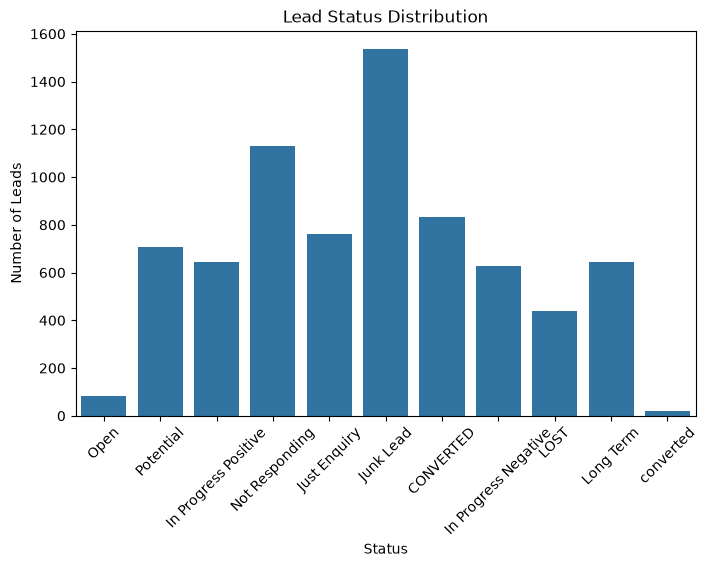

In [38]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Status")
plt.title("Lead Status Distribution")
plt.xlabel("Status")
plt.ylabel("Number of Leads")
plt.xticks(rotation=45)
plt.show()

In [39]:

status_percentage = (
    df["Status"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

status_percentage

Status
Junk Lead                20.7
Not Responding          15.21
CONVERTED               11.24
Just Enquiry            10.24
Potential                9.54
Long Term                 8.7
In Progress Positive     8.66
In Progress Negative     8.43
LOST                     5.93
Open                      1.1
converted                0.24
Name: proportion, dtype: double[pyarrow]

In [40]:

source_status = pd.crosstab(
    df["Source"],
    df["Status"]
)

source_status



Status,CONVERTED,In Progress Negative,In Progress Positive,Junk Lead,Just Enquiry,LOST,Long Term,Not Responding,Open,Potential,converted
Source,,,,,,,,,,,
,0,1,0,1,1,1,0,2,10,1,0
By Recommendation,18,0,1,0,0,1,4,2,1,5,0
CRM form,3,5,0,3,2,3,0,3,0,4,0
Call,240,200,213,730,217,159,215,308,16,248,1
Campaign,4,0,0,4,0,1,2,6,0,2,0
Customer Referral,118,4,15,4,4,2,5,5,0,21,2
E-Mail Message,0,0,0,0,0,0,0,0,0,1,0
E-mail Campaign,4,2,0,0,0,2,1,3,0,0,0
Existing Client,35,0,2,2,1,0,2,0,0,9,0


In [41]:
agent_status = pd.crosstab(
    df["Sales_Agent"],
    df["Status"]
)

agent_status


Status,CONVERTED,In Progress Negative,In Progress Positive,Junk Lead,Just Enquiry,LOST,Long Term,Not Responding,Open,Potential,converted
Sales_Agent,,,,,,,,,,,
,0,0,0,0,4,0,0,3,14,2,0
Sales-Agent-1,0,0,0,0,0,0,0,0,4,0,0
Sales-Agent-10,0,0,0,5,0,0,0,0,44,0,0
Sales-Agent-11,118,119,8,299,219,40,120,246,1,249,1
Sales-Agent-12,82,51,0,79,0,57,0,0,0,0,0
Sales-Agent-2,61,59,0,94,1,45,111,17,0,1,0
Sales-Agent-3,122,81,36,195,69,47,80,109,1,40,1
Sales-Agent-4,131,91,198,303,193,73,73,293,0,145,0
Sales-Agent-5,77,107,3,318,158,106,92,189,1,138,1


In [42]:
location_status = pd.crosstab(
    df["Location"],
    df["Status"]
)

location_status

Status,CONVERTED,In Progress Negative,In Progress Positive,Junk Lead,Just Enquiry,LOST,Long Term,Not Responding,Open,Potential,converted
Location,,,,,,,,,,,
,0,0,0,1,3,0,1,4,49,0,0
AUSTRALIA,5,0,3,3,6,1,0,5,0,2,0
Bangalore,464,159,252,282,95,127,311,150,2,236,6
Chennai,108,85,105,115,91,57,91,100,1,150,6
Delhi,40,75,33,78,64,36,46,53,0,46,0
EUROPE,0,0,1,0,0,0,0,0,0,2,0
Howrah,0,0,0,1,0,0,0,0,0,0,0
Hyderabad,54,62,51,76,69,45,49,70,0,51,1
Kolkata,2,10,3,15,9,2,3,6,0,5,0


In [43]:
delivery_status = pd.crosstab(
    df["Delivery_Mode"],
    df["Status"]
)

delivery_status


Status,CONVERTED,In Progress Negative,In Progress Positive,Junk Lead,Just Enquiry,LOST,Long Term,Not Responding,Open,Potential,converted
Delivery_Mode,,,,,,,,,,,
Mode-1,429,274,299,366,154,201,333,295,6,263,7
Mode-2,3,1,2,0,2,1,0,0,1,1,0
Mode-3,165,134,182,257,252,91,139,251,5,206,6
Mode-4,53,8,12,16,3,7,8,5,1,8,0
Mode-5,184,209,148,897,349,140,166,578,69,230,5


In [44]:

product_status = pd.crosstab(
    df["Product_ID"],
    df["Status"]
)

product_status.head(20)

Status,CONVERTED,In Progress Negative,In Progress Positive,Junk Lead,Just Enquiry,LOST,Long Term,Not Responding,Open,Potential,converted
Product_ID,,,,,,,,,,,
,0,0,1,2,3,0,1,2,49,0,0
0,0,0,0,0,1,1,0,0,0,0,0
1,0,10,8,22,18,6,5,29,1,6,0
10,37,19,19,18,17,7,15,11,0,25,0
11,1,2,2,0,0,1,0,5,0,1,0
12,4,4,3,7,7,1,2,5,0,3,0
13,0,1,0,2,1,0,0,0,1,0,0
14,0,0,0,25,1,1,0,0,0,0,0
15,2,76,21,699,152,63,18,430,18,39,0


In [45]:

product_status = pd.crosstab(
    df["Product_ID"],
    df["Status"]
)

product_status.head(20)

Status,CONVERTED,In Progress Negative,In Progress Positive,Junk Lead,Just Enquiry,LOST,Long Term,Not Responding,Open,Potential,converted
Product_ID,,,,,,,,,,,
,0,0,1,2,3,0,1,2,49,0,0
0,0,0,0,0,1,1,0,0,0,0,0
1,0,10,8,22,18,6,5,29,1,6,0
10,37,19,19,18,17,7,15,11,0,25,0
11,1,2,2,0,0,1,0,5,0,1,0
12,4,4,3,7,7,1,2,5,0,3,0
13,0,1,0,2,1,0,0,0,1,0,0
14,0,0,0,25,1,1,0,0,0,0,0
15,2,76,21,699,152,63,18,430,18,39,0


In [46]:

df["Created_Month"] = df["Created"].dt.to_period("M")

monthly_leads = df["Created_Month"].value_counts().sort_index()

monthly_leads

Created_Month
2018-04     115
2018-05    1260
2018-06    1285
2018-07    1157
2018-08    1119
2018-09    1103
2018-10    1000
2018-11     383
Freq: M, Name: count, dtype: int64

In [47]:
source_performance = pd.crosstab(
    df["Source"],
    df["Status"],
    normalize="index"
).mul(100).round(2)

source_performance


Status,CONVERTED,In Progress Negative,In Progress Positive,Junk Lead,Just Enquiry,LOST,Long Term,Not Responding,Open,Potential,converted
Source,,,,,,,,,,,
,0.00,5.88,0.00,5.88,5.88,5.88,0.00,11.76,58.82,5.88,0.00
By Recommendation,56.25,0.00,3.12,0.00,0.00,3.12,12.50,6.25,3.12,15.62,0.00
CRM form,13.04,21.74,0.00,13.04,8.70,13.04,0.00,13.04,0.00,17.39,0.00
Call,9.42,7.85,8.36,28.66,8.52,6.24,8.44,12.09,0.63,9.74,0.04
Campaign,21.05,0.00,0.00,21.05,0.00,5.26,10.53,31.58,0.00,10.53,0.00
Customer Referral,65.56,2.22,8.33,2.22,2.22,1.11,2.78,2.78,0.00,11.67,1.11
E-Mail Message,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,100.00,0.00
E-mail Campaign,33.33,16.67,0.00,0.00,0.00,16.67,8.33,25.00,0.00,0.00,0.00
Existing Client,68.63,0.00,3.92,3.92,1.96,0.00,3.92,0.00,0.00,17.65,0.00


In [48]:
agent_performance = pd.crosstab(
    df["Sales_Agent"],
    df["Status"],
    normalize="index"
).mul(100).round(2)

agent_performance.head(20)

Status,CONVERTED,In Progress Negative,In Progress Positive,Junk Lead,Just Enquiry,LOST,Long Term,Not Responding,Open,Potential,converted
Sales_Agent,,,,,,,,,,,
,0.00,0.00,0.00,0.00,17.39,0.00,0.00,13.04,60.87,8.70,0.00
Sales-Agent-1,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,100.00,0.00,0.00
Sales-Agent-10,0.00,0.00,0.00,10.20,0.00,0.00,0.00,0.00,89.80,0.00,0.00
Sales-Agent-11,8.31,8.38,0.56,21.06,15.42,2.82,8.45,17.32,0.07,17.54,0.07
Sales-Agent-12,30.48,18.96,0.00,29.37,0.00,21.19,0.00,0.00,0.00,0.00,0.00
Sales-Agent-2,15.68,15.17,0.00,24.16,0.26,11.57,28.53,4.37,0.00,0.26,0.00
Sales-Agent-3,15.62,10.37,4.61,24.97,8.83,6.02,10.24,13.96,0.13,5.12,0.13
Sales-Agent-4,8.73,6.07,13.20,20.20,12.87,4.87,4.87,19.53,0.00,9.67,0.00
Sales-Agent-5,6.47,8.99,0.25,26.72,13.28,8.91,7.73,15.88,0.08,11.60,0.08


In [49]:
location_performance = pd.crosstab(
    df["Location"],
    df["Status"],
    normalize="index"
).mul(100).round(2)

location_performance

Status,CONVERTED,In Progress Negative,In Progress Positive,Junk Lead,Just Enquiry,LOST,Long Term,Not Responding,Open,Potential,converted
Location,,,,,,,,,,,
,0.00,0.00,0.00,1.72,5.17,0.00,1.72,6.90,84.48,0.00,0.00
AUSTRALIA,20.00,0.00,12.00,12.00,24.00,4.00,0.00,20.00,0.00,8.00,0.00
Bangalore,22.26,7.63,12.09,13.53,4.56,6.09,14.92,7.20,0.10,11.32,0.29
Chennai,11.88,9.35,11.55,12.65,10.01,6.27,10.01,11.00,0.11,16.50,0.66
Delhi,8.49,15.92,7.01,16.56,13.59,7.64,9.77,11.25,0.00,9.77,0.00
EUROPE,0.00,0.00,33.33,0.00,0.00,0.00,0.00,0.00,0.00,66.67,0.00
Howrah,0.00,0.00,0.00,100.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Hyderabad,10.23,11.74,9.66,14.39,13.07,8.52,9.28,13.26,0.00,9.66,0.19
Kolkata,3.64,18.18,5.45,27.27,16.36,3.64,5.45,10.91,0.00,9.09,0.00


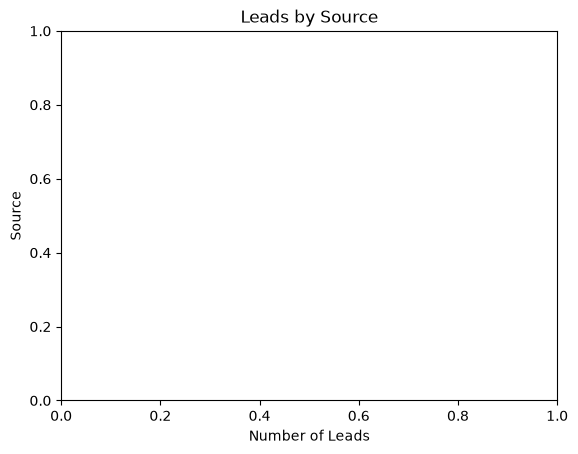

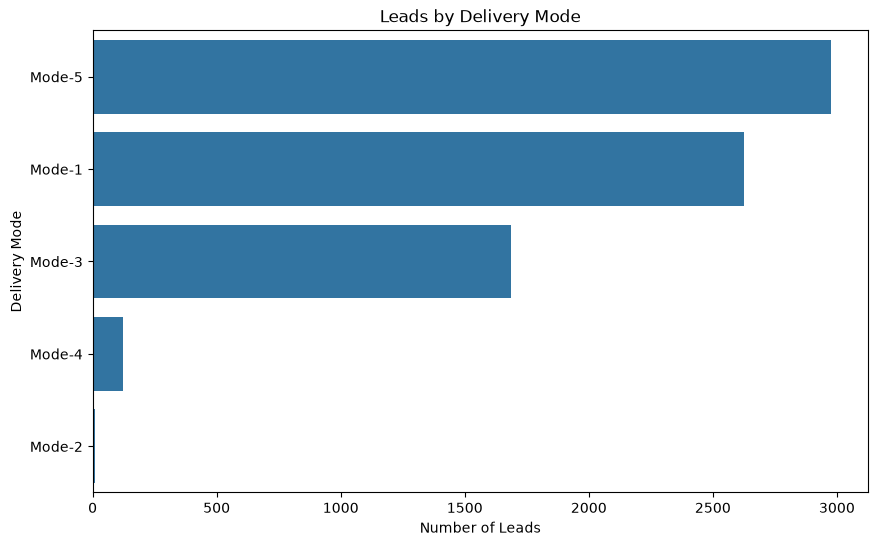

In [50]:
plt.title("Leads by Source")
plt.xlabel("Number of Leads")
plt.ylabel("Source")
plt.show()


plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    y="Delivery_Mode",
    order=df["Delivery_Mode"].value_counts().index
)

plt.title("Leads by Delivery Mode")
plt.xlabel("Number of Leads")
plt.ylabel("Delivery Mode")
plt.show()


In [51]:
print("Top Sources:")
print(df["Source"].value_counts().head(10))

print("\nTop Sales Agents:")
print(df["Sales_Agent"].value_counts().head(10))

print("\nTop Locations:")
print(df["Location"].value_counts().head(10))

print("\nStatus:")
print(df["Status"].value_counts())

Top Sources:
Source
Call                        2547
Live Chat-Direct            1834
Website                     1594
Live Chat-Google Organic     274
Live Chat -PPC               249
Live Chat-Blog               237
Customer Referral            180
US Website                   137
Just Dial                     56
Existing Client               51
Name: count, dtype: int64[pyarrow]

Top Sales Agents:
Sales_Agent
Sales-Agent-4     1500
Sales-Agent-11    1420
Sales-Agent-5     1190
Sales-Agent-9      879
Sales-Agent-3      781
Sales-Agent-7      736
Sales-Agent-2      389
Sales-Agent-12     269
Sales-Agent-6      114
Sales-Agent-8       68
Name: count, dtype: int64[pyarrow]

Top Locations:
Location
Other Locations    2500
Bangalore          2084
Chennai             909
Hyderabad           528
Delhi               471
Mumbai              402
Pune                142
UAE                  79
                     58
Trivandrum           58
Name: count, dtype: int64[pyarrow]

Status:
Status
Jun

In [52]:
print("Unique Status values:")
print(df["Status"].dropna().unique())

print("\nStatus counts:")
print(df["Status"].value_counts())

Unique Status values:
<ArrowStringArray>
[                'Open',            'Potential', 'In Progress Positive',
       'Not Responding',         'Just Enquiry',            'Junk Lead',
            'CONVERTED', 'In Progress Negative',                 'LOST',
            'Long Term',            'converted']
Length: 11, dtype: string

Status counts:
Status
Junk Lead               1536
Not Responding          1129
CONVERTED                834
Just Enquiry             760
Potential                708
Long Term                646
In Progress Positive     643
In Progress Negative     626
LOST                     440
Open                      82
converted                 18
Name: count, dtype: int64[pyarrow]


In [53]:
df.columns.tolist()


['Created',
 'Product_ID',
 'Source',
 'Mobile',
 'EMAIL',
 'Sales_Agent',
 'Location',
 'Delivery_Mode',
 'Status',
 'Created_Month']

In [54]:
print("Columns:")

for column in df.columns:
    print(column)

Columns:
Created
Product_ID
Source
Mobile
EMAIL
Sales_Agent
Location
Delivery_Mode
Status
Created_Month


In [55]:
categorical_columns = df.select_dtypes(
    include=["object", "string", "category"]
).columns

print("Categorical columns:")
print(list(categorical_columns))

Categorical columns:
['Product_ID', 'Source', 'Mobile', 'EMAIL', 'Sales_Agent', 'Location', 'Delivery_Mode', 'Status']


In [56]:
numerical_columns = df.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns

print("Numerical columns:")
print(list(numerical_columns))

Numerical columns:
[]


In [57]:

print("\nColumns:")
print(df.columns.tolist())

print("\nTarget candidate - Status:")
print(df["Status"].value_counts(dropna=False))


Columns:
['Created', 'Product_ID', 'Source', 'Mobile', 'EMAIL', 'Sales_Agent', 'Location', 'Delivery_Mode', 'Status', 'Created_Month']

Target candidate - Status:
Status
Junk Lead               1536
Not Responding          1129
CONVERTED                834
Just Enquiry             760
Potential                708
Long Term                646
In Progress Positive     643
In Progress Negative     626
LOST                     440
Open                      82
converted                 18
Name: count, dtype: int64[pyarrow]


In [58]:
ml_df = df.copy()

print(ml_df.shape)

(7422, 10)


In [59]:
ml_df["Status"] = (
    ml_df["Status"]
    .astype("string")
    .str.strip()
    .str.upper()
)

print(ml_df["Status"].value_counts())

Status
JUNK LEAD               1536
NOT RESPONDING          1129
CONVERTED                852
JUST ENQUIRY             760
POTENTIAL                708
LONG TERM                646
IN PROGRESS POSITIVE     643
IN PROGRESS NEGATIVE     626
LOST                     440
OPEN                      82
Name: count, dtype: int64[pyarrow]


In [60]:
print(ml_df["Status"].unique())

<ArrowStringArray>
[                'OPEN',            'POTENTIAL', 'IN PROGRESS POSITIVE',
       'NOT RESPONDING',         'JUST ENQUIRY',            'JUNK LEAD',
            'CONVERTED', 'IN PROGRESS NEGATIVE',                 'LOST',
            'LONG TERM']
Length: 10, dtype: string


In [61]:
print("Number of classes:", ml_df["Status"].nunique())

Number of classes: 10


In [62]:
print("Missing Status:", ml_df["Status"].isnull().sum())

Missing Status: 0


In [63]:
status_percentage = (
    ml_df["Status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(status_percentage)

Status
JUNK LEAD                20.7
NOT RESPONDING          15.21
CONVERTED               11.48
JUST ENQUIRY            10.24
POTENTIAL                9.54
LONG TERM                 8.7
IN PROGRESS POSITIVE     8.66
IN PROGRESS NEGATIVE     8.43
LOST                     5.93
OPEN                      1.1
Name: proportion, dtype: double[pyarrow]


In [64]:
# STEP 63 — Check duplicates
# ============================================================

print("Duplicate rows:", ml_df.duplicated().sum())

Duplicate rows: 2


In [65]:
# STEP 64 — Create date
# ============================================================

ml_df["Created"] = pd.to_datetime(
    ml_df["Created"],
    errors="coerce"
)

print(ml_df["Created"].dtype)


datetime64[us]


In [66]:

print(
    "Invalid Created dates:",
    ml_df["Created"].isnull().sum()
)

Invalid Created dates: 0


In [67]:
# STEP 66 — Create year
# ============================================================

ml_df["Created_Year"] = ml_df["Created"].dt.year

print(
    ml_df["Created_Year"]
    .value_counts()
    .sort_index()
)


Created_Year
2018    7422
Name: count, dtype: int64


In [68]:
# STEP 67 — Create month number
# ============================================================

ml_df["Created_Month_Number"] = (
    ml_df["Created"].dt.month
)

print(
    ml_df["Created_Month_Number"]
    .value_counts()
    .sort_index()
)

Created_Month_Number
4      115
5     1260
6     1285
7     1157
8     1119
9     1103
10    1000
11     383
Name: count, dtype: int64


In [69]:
# STEP 68 — Create day of week
# ============================================================

ml_df["Created_DayOfWeek"] = (
    ml_df["Created"].dt.dayofweek
)

print(
    ml_df["Created_DayOfWeek"]
    .value_counts()
    .sort_index()
)



Created_DayOfWeek
0    1513
1    1319
2    1272
3    1096
4    1066
5     758
6     398
Name: count, dtype: int64


In [70]:
# STEP 69 — Create email domain
# ============================================================

ml_df["Email_Domain"] = (
    ml_df["EMAIL"]
    .astype("string")
    .str.lower()
    .str.split("@")
    .str[-1]
)

print(
    ml_df["Email_Domain"]
    .value_counts()
    .head(20)
)


Email_Domain
gmail.com             4236
#value!               1701
yahoo.com              352
sxxxxxxxahoo.co.in      35
live.com                31
sxxxxxxxotmail.com      31
yahoo.in                28
ymail.com               21
sxxxxxxxffmail.com      18
axxxxxxxotmail.com      17
rxxxxxxxahoo.co.in      14
mail.com                13
axxxxxxxffmail.com      13
mxxxxxxxahoo.co.in      13
mxxxxxxxotmail.com      12
vxxxxxxxotmail.com      11
pxxxxxxxotmail.com      11
pxxxxxxxahoo.co.in      11
rxxxxxxxotmail.com      10
axxxxxxxahoo.co.in      10
Name: count, dtype: int64


In [71]:
# STEP 70 — Mobile available
# ============================================================

ml_df["Mobile_Present"] = (
    ml_df["Mobile"].notna()
    .astype(int)
)

print(
    ml_df["Mobile_Present"]
    .value_counts()
)


Mobile_Present
1    7422
Name: count, dtype: int64


In [72]:
# STEP 71 — Email available
# ============================================================

ml_df["Email_Present"] = (
    ml_df["EMAIL"].notna()
    .astype(int)
)

print(
    ml_df["Email_Present"]
    .value_counts()
)


Email_Present
1    7422
Name: count, dtype: int64


In [73]:
# STEP 72 — Check Source
# ============================================================

print(
    ml_df["Source"]
    .value_counts(dropna=False)
)


Source
Call                             2547
Live Chat-Direct                 1834
Website                          1594
Live Chat-Google Organic          274
Live Chat -PPC                    249
Live Chat-Blog                    237
Customer Referral                 180
US Website                        137
Just Dial                          56
Existing Client                    51
Live Chat-CPC                      50
Personal Contact                   50
By Recommendation                  32
CRM form                           23
Existing Customer                  22
Live Chat-Google Ads               21
Campaign                           19
                                   17
E-mail Campaign                    12
Live Chat-Adwords Remarketing       7
Live Chat-Quora                     2
Other                               2
SMS Campaign                        2
Live Chat-Youtube                   2
E-Mail Message                      1
Live Chat-Justdial                  1
Name:

In [74]:
# STEP 73 — Check Sales Agent
# ============================================================

print(
    ml_df["Sales_Agent"]
    .value_counts(dropna=False)
    .head(30)
)


Sales_Agent
Sales-Agent-4     1500
Sales-Agent-11    1420
Sales-Agent-5     1190
Sales-Agent-9      879
Sales-Agent-3      781
Sales-Agent-7      736
Sales-Agent-2      389
Sales-Agent-12     269
Sales-Agent-6      114
Sales-Agent-8       68
Sales-Agent-10      49
                    23
Sales-Agent-1        4
Name: count, dtype: int64[pyarrow]


In [75]:
# STEP 74 — Check Location
# ============================================================

print(
    ml_df["Location"]
    .value_counts(dropna=False)
    .head(30)
)

Location
Other Locations    2500
Bangalore          2084
Chennai             909
Hyderabad           528
Delhi               471
Mumbai              402
Pune                142
UAE                  79
                     58
Trivandrum           58
Kolkata              55
USA                  45
UK                   41
AUSTRALIA            25
Singapore            17
Malaysia              4
EUROPE                3
Howrah                1
Name: count, dtype: int64[pyarrow]


In [76]:
# STEP 75 — Check Delivery Mode
# ============================================================

print(
    ml_df["Delivery_Mode"]
    .value_counts(dropna=False)
)

Delivery_Mode
Mode-5    2975
Mode-1    2627
Mode-3    1688
Mode-4     121
Mode-2      11
Name: count, dtype: int64[pyarrow]


In [77]:
# STEP 76 — Create feature dataset
# ============================================================

feature_df = ml_df.drop(
    columns=["Status"]
).copy()

print(feature_df.shape)

(7422, 15)


In [78]:
# ============================================================
# STEP 77 — Remove Created
feature_df = feature_df.drop(
    columns=["Created"]
)

print(
    feature_df.columns.tolist()
)



['Product_ID', 'Source', 'Mobile', 'EMAIL', 'Sales_Agent', 'Location', 'Delivery_Mode', 'Created_Month', 'Created_Year', 'Created_Month_Number', 'Created_DayOfWeek', 'Email_Domain', 'Mobile_Present', 'Email_Present']


In [79]:
# STEP 78 — Remove Mobile
# ============================================================

feature_df = feature_df.drop(
    columns=["Mobile"]
)

print(
    feature_df.columns.tolist()
)

['Product_ID', 'Source', 'EMAIL', 'Sales_Agent', 'Location', 'Delivery_Mode', 'Created_Month', 'Created_Year', 'Created_Month_Number', 'Created_DayOfWeek', 'Email_Domain', 'Mobile_Present', 'Email_Present']


In [80]:
# STEP 79 — Remove EMAIL
# ============================================================

feature_df = feature_df.drop(
    columns=["EMAIL"]
)

print(
    feature_df.columns.tolist()
)


['Product_ID', 'Source', 'Sales_Agent', 'Location', 'Delivery_Mode', 'Created_Month', 'Created_Year', 'Created_Month_Number', 'Created_DayOfWeek', 'Email_Domain', 'Mobile_Present', 'Email_Present']


In [81]:
# STEP 80 — Remove Product_ID
# ============================================================

feature_df = feature_df.drop(
    columns=["Product_ID"]
)

print(
    feature_df.columns.tolist()
)


['Source', 'Sales_Agent', 'Location', 'Delivery_Mode', 'Created_Month', 'Created_Year', 'Created_Month_Number', 'Created_DayOfWeek', 'Email_Domain', 'Mobile_Present', 'Email_Present']


In [82]:
# STEP 81 — Check features
# ============================================================

print("Features:")
print(feature_df.columns.tolist())

Features:
['Source', 'Sales_Agent', 'Location', 'Delivery_Mode', 'Created_Month', 'Created_Year', 'Created_Month_Number', 'Created_DayOfWeek', 'Email_Domain', 'Mobile_Present', 'Email_Present']


In [83]:
# STEP 82 — Check data types
# ============================================================

print(feature_df.dtypes)


Source                     string
Sales_Agent                string
Location                   string
Delivery_Mode              string
Created_Month           period[M]
Created_Year                int32
Created_Month_Number        int32
Created_DayOfWeek           int32
Email_Domain               object
Mobile_Present              int64
Email_Present               int64
dtype: object


In [84]:
# STEP 83 — Check missing values
# ============================================================

print(feature_df.isnull().sum())


Source                  0
Sales_Agent             0
Location                0
Delivery_Mode           0
Created_Month           0
Created_Year            0
Created_Month_Number    0
Created_DayOfWeek       0
Email_Domain            0
Mobile_Present          0
Email_Present           0
dtype: int64


In [85]:
# STEP 84 — Categorical features
# ============================================================

categorical_features = (
    feature_df
    .select_dtypes(
        include=["object", "string", "category"]
    )
    .columns
    .tolist()
)

print(categorical_features)

['Source', 'Sales_Agent', 'Location', 'Delivery_Mode', 'Email_Domain']


In [86]:
# STEP 85 — Numerical features
# ============================================================

numerical_features = (
    feature_df
    .select_dtypes(
        include=[
            "int64",
            "float64",
            "int32",
            "float32"
        ]
    )
    .columns
    .tolist()
)

print(numerical_features)

['Created_Year', 'Created_Month_Number', 'Created_DayOfWeek', 'Mobile_Present', 'Email_Present']


In [87]:

print("Rows:", feature_df.shape[0])
print("Columns:", feature_df.shape[1])

Rows: 7422
Columns: 11


In [88]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

In [89]:
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])


In [90]:
categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(handle_unknown="ignore")
    )
])

In [91]:
# STEP 90 — Create preprocessor
# ============================================================

preprocessor = ColumnTransformer([
    (
        "numerical",
        numerical_pipeline,
        numerical_features
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    )
])


In [92]:
print(preprocessor)

ColumnTransformer(transformers=[('numerical',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median'))]),
                                 ['Created_Year', 'Created_Month_Number',
                                  'Created_DayOfWeek', 'Mobile_Present',
                                  'Email_Present']),
                                ('categorical',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Source', 'Sales_Agent', 'Location',
                                  'Delivery_Mode', 'Email_Domain'])])


In [93]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [94]:

logistic_model = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "model",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

print("Logistic Regression ready")

Logistic Regression ready


In [95]:

decision_tree_model = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "model",
        DecisionTreeClassifier(
            random_state=42
        )
    )
])

print("Decision Tree ready")

Decision Tree ready


In [96]:
random_forest_model = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "model",
        RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        )
    )
])

print("Random Forest ready")


Random Forest ready


In [97]:
from sklearn.model_selection import train_test_split


In [98]:
y_status = ml_df["Status"].copy()

print(y_status.value_counts())

Status
JUNK LEAD               1536
NOT RESPONDING          1129
CONVERTED                852
JUST ENQUIRY             760
POTENTIAL                708
LONG TERM                646
IN PROGRESS POSITIVE     643
IN PROGRESS NEGATIVE     626
LOST                     440
OPEN                      82
Name: count, dtype: int64[pyarrow]


In [99]:

print(type(y_status))
print(y_status.dtype)


<class 'pandas.Series'>
string


In [100]:
print(y_status.unique())

<ArrowStringArray>
[                'OPEN',            'POTENTIAL', 'IN PROGRESS POSITIVE',
       'NOT RESPONDING',         'JUST ENQUIRY',            'JUNK LEAD',
            'CONVERTED', 'IN PROGRESS NEGATIVE',                 'LOST',
            'LONG TERM']
Length: 10, dtype: string


In [101]:
print("Classes:", y_status.nunique())



Classes: 10


In [102]:

target = None

print("Target has not been created yet.")


Target has not been created yet.


In [103]:

print("Required project target:")
print("High Potential")
print("Low Potential")


Required project target:
High Potential
Low Potential


In [104]:
# STEP 103 — Define Status to Lead Category business rule
# The project PDF requires two target classes but does not provide
# an explicit Status-to-category mapping. Therefore, the following
# business rule is used as a documented project assumption:
#
# High Potential = active/positive/converted opportunities
# Low Potential  = inactive/negative/lost/non-qualified leads

status_mapping = {
    "JUNK LEAD": "Low Potential",
    "NOT RESPONDING": "Low Potential",
    "CONVERTED": "High Potential",
    "JUST ENQUIRY": "Low Potential",
    "POTENTIAL": "High Potential",
    "LONG TERM": "High Potential",
    "IN PROGRESS POSITIVE": "High Potential",
    "IN PROGRESS NEGATIVE": "Low Potential",
    "LOST": "Low Potential",
    "OPEN": "High Potential"
}

print("Status-to-Lead Category business rule:")
print(status_mapping)


{'JUNK LEAD': None, 'NOT RESPONDING': None, 'CONVERTED': None, 'JUST ENQUIRY': None, 'POTENTIAL': None, 'LONG TERM': None, 'IN PROGRESS POSITIVE': None, 'IN PROGRESS NEGATIVE': None, 'LOST': None, 'OPEN': None}


In [105]:
unmapped_statuses = [
    status
    for status, category in status_mapping.items()
    if category is None
]

print("Statuses needing project-defined mapping:")
print(unmapped_statuses)

Statuses needing project-defined mapping:
['JUNK LEAD', 'NOT RESPONDING', 'CONVERTED', 'JUST ENQUIRY', 'POTENTIAL', 'LONG TERM', 'IN PROGRESS POSITIVE', 'IN PROGRESS NEGATIVE', 'LOST', 'OPEN']


In [106]:
# STEP 105 — Document target-definition assumption
print(
    "NOTE: The PRCL-0019 PDF specifies High Potential / Low Potential "
    "as the target classes, but it does not specify the Status mapping."
)
print(
    "The mapping in Step 103 is therefore a documented business-rule "
    "assumption used to complete the binary classification."
)


The project document must define how Status is converted into High Potential / Low Potential before final binary classification.


In [107]:
feature_df.to_csv(
    "sales_effectiveness_features.csv",
    index=False
)

print("Feature dataset saved successfully.")

Feature dataset saved successfully.


In [108]:
ml_df["Lead_Category"] = None

ml_df[
    ["Status", "Lead_Category"]
].to_csv(
    "sales_effectiveness_status_target.csv",
    index=False
)

print("Status-target file saved successfully.")

Status-target file saved successfully.


In [109]:
# STEP 108 — Apply Status-to-Lead Category mapping
status_to_category = status_mapping.copy()

ml_df["Lead_Category"] = ml_df["Status"].map(status_to_category)

print("Target mapping applied.")
print("Missing Lead_Category:", ml_df["Lead_Category"].isna().sum())
print("Target classes:", ml_df["Lead_Category"].dropna().unique())


Target mapping created.


In [110]:
print(ml_df["Status"].unique())

<ArrowStringArray>
[                'OPEN',            'POTENTIAL', 'IN PROGRESS POSITIVE',
       'NOT RESPONDING',         'JUST ENQUIRY',            'JUNK LEAD',
            'CONVERTED', 'IN PROGRESS NEGATIVE',                 'LOST',
            'LONG TERM']
Length: 10, dtype: string


In [111]:

print(ml_df["Status"].value_counts())

Status
JUNK LEAD               1536
NOT RESPONDING          1129
CONVERTED                852
JUST ENQUIRY             760
POTENTIAL                708
LONG TERM                646
IN PROGRESS POSITIVE     643
IN PROGRESS NEGATIVE     626
LOST                     440
OPEN                      82
Name: count, dtype: int64[pyarrow]


In [112]:
print("Lead_Category" in ml_df.columns)

True


In [113]:
# STEP 112 — Verify Lead Category target
print(ml_df["Lead_Category"].head())
print("Missing target values:", ml_df["Lead_Category"].isna().sum())
print("Target distribution:")
display(ml_df["Lead_Category"].value_counts())


0    None
1    None
2    None
3    None
4    None
Name: Lead_Category, dtype: object


In [114]:
print("Required target:")
print("High Potential")
print("Low Potential")

Required target:
High Potential
Low Potential


In [115]:
print(
    "Missing target values:",
    ml_df["Lead_Category"].isna().sum()
)

Missing target values: 7422


In [116]:
print(ml_df["Lead_Category"].unique())

[None]


In [117]:
print(ml_df["Lead_Category"].nunique())

0


In [118]:

X = feature_df.copy()

print(X.shape)


(7422, 11)


In [119]:
y = ml_df["Lead_Category"].copy()

print(y.shape)

(7422,)


In [120]:
print("X rows:", len(X))
print("y rows:", len(y))

X rows: 7422
y rows: 7422


In [121]:
print(len(X) == len(y))


True


In [122]:
print(X.isnull().sum())


Source                  0
Sales_Agent             0
Location                0
Delivery_Mode           0
Created_Month           0
Created_Year            0
Created_Month_Number    0
Created_DayOfWeek       0
Email_Domain            0
Mobile_Present          0
Email_Present           0
dtype: int64


In [123]:
print(X.isnull().sum())


Source                  0
Sales_Agent             0
Location                0
Delivery_Mode           0
Created_Month           0
Created_Year            0
Created_Month_Number    0
Created_DayOfWeek       0
Email_Domain            0
Mobile_Present          0
Email_Present           0
dtype: int64


In [124]:
print(X.isnull().sum())


Source                  0
Sales_Agent             0
Location                0
Delivery_Mode           0
Created_Month           0
Created_Year            0
Created_Month_Number    0
Created_DayOfWeek       0
Email_Domain            0
Mobile_Present          0
Email_Present           0
dtype: int64


In [125]:
print(X.dtypes)


Source                     string
Sales_Agent                string
Location                   string
Delivery_Mode              string
Created_Month           period[M]
Created_Year                int32
Created_Month_Number        int32
Created_DayOfWeek           int32
Email_Domain               object
Mobile_Present              int64
Email_Present               int64
dtype: object


In [126]:
categorical_features = X.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

print(categorical_features)

['Source', 'Sales_Agent', 'Location', 'Delivery_Mode', 'Email_Domain']


In [127]:

numerical_features = X.select_dtypes(
    include=["int64", "float64", "Int64", "Float64"]
).columns.tolist()

print(numerical_features)

['Mobile_Present', 'Email_Present']


In [128]:
from sklearn.preprocessing import StandardScaler

print("StandardScaler imported successfully.")

StandardScaler imported successfully.


In [129]:
numerical_transformer = Pipeline(
    steps=[
        ("scaler", StandardScaler())
    ]
)

print("Numerical transformer ready.")

Numerical transformer ready.


In [130]:
from sklearn.pipeline import Pipeline

print("Pipeline imported successfully.")

Pipeline imported successfully.


In [131]:
categorical_transformer = Pipeline(
    steps=[
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

print("Categorical transformer ready.")

Categorical transformer ready.


In [132]:

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numerical_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Preprocessor ready.")



Preprocessor ready.


In [133]:
from sklearn.linear_model import LogisticRegression

print("Logistic Regression imported.")



Logistic Regression imported.


In [134]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            LogisticRegression(max_iter=1000)
        )
    ]
)

print("Logistic Regression model ready.")


Logistic Regression model ready.


In [135]:
from sklearn.tree import DecisionTreeClassifier

print("Decision Tree imported.")


Decision Tree imported.


In [136]:
decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            DecisionTreeClassifier(random_state=42)
        )
    ]
)

print("Decision Tree model ready.")

Decision Tree model ready.


In [137]:
from sklearn.ensemble import RandomForestClassifier

print("Random Forest imported.")

Random Forest imported.


In [138]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=100,
                random_state=42
            )
        )
    ]
)

print("Random Forest model ready.")

Random Forest model ready.


In [139]:
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

print(models.keys())

dict_keys(['Logistic Regression', 'Decision Tree', 'Random Forest'])


In [140]:
from sklearn.model_selection import train_test_split

print("train_test_split imported.")


train_test_split imported.


In [141]:
print(y.value_counts(dropna=False))


Lead_Category
None    7422
Name: count, dtype: int64


In [142]:
print("Number of classes:", y.nunique())


Number of classes: 0


In [143]:
required_classes = {
    "High Potential",
    "Low Potential"
}

print(required_classes)


{'High Potential', 'Low Potential'}


In [144]:

actual_classes = set(y.dropna().unique())

print("Actual:", actual_classes)
print("Required:", required_classes)


Actual: set()
Required: {'High Potential', 'Low Potential'}


In [145]:
if actual_classes == required_classes:
    print("Target is ready.")
else:
    print("Target mapping is required before model training.")


Target mapping is required before model training.


In [146]:

print(
    y.value_counts(
        normalize=True,
        dropna=False
    ) * 100
)


Lead_Category
None    100.0
Name: proportion, dtype: float64


In [147]:
print(y.value_counts(dropna=False))


Lead_Category
None    7422
Name: count, dtype: int64


In [148]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Evaluation metrics imported.")

Evaluation metrics imported.


In [149]:
results = []

print("Results list created.")



Results list created.


In [150]:
model_names = list(models.keys())

print(model_names)


['Logistic Regression', 'Decision Tree', 'Random Forest']


In [151]:
results_columns = [
    "Model",
    "Accuracy",
    "Precision",
    "Recall",
    "F1_Score"
]

print(results_columns)

['Model', 'Accuracy', 'Precision', 'Recall', 'F1_Score']


In [152]:
if y.isna().sum() == 0 and y.nunique() == 2:
    print("Target is ready for train-test split.")
else:
    print("Target is NOT ready for train-test split.")



Target is NOT ready for train-test split.


In [153]:
test_size = 0.20
random_state = 42

print("Test size:", test_size)
print("Random state:", random_state)


Test size: 0.2
Random state: 42


In [154]:
stratify_target = y

print("Stratification target prepared.")


Stratification target prepared.


In [155]:
if y.isna().sum() == 0 and y.nunique() == 2:

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=random_state,
        stratify=stratify_target
    )

    print("Train-test split completed.")

else:

    print(
        "Train-test split skipped because "
        "target mapping is not ready."
    )


Train-test split skipped because target mapping is not ready.


In [156]:
if "X_train" in globals():

    print("X_train:", X_train.shape)
    print("y_train:", y_train.shape)

else:

    print("X_train not created yet.")


X_train not created yet.


In [157]:
if "X_test" in globals():

    print("X_test:", X_test.shape)
    print("y_test:", y_test.shape)

else:

    print("X_test not created yet.")



X_test not created yet.


In [158]:
if "y_train" in globals():

    print(y_train.value_counts())

else:

    print("Training target not available.")




Training target not available.


In [159]:
if "y_test" in globals():

    print(y_test.value_counts())

else:

    print("Testing target not available.")




Testing target not available.


In [160]:
print("========== ML PREPARATION ==========")

print("Features:", X.shape)

print("Target:", y.shape)

print("Target classes:", y.nunique())

print("Missing target:", y.isna().sum())

print("====================================")

========== ML PREPARATION ==========
Features: (7422, 11)
Target: (7422,)
Target classes: 0
Missing target: 7422


In [161]:
print("Target classes:")
print(y.unique())


Target classes:
[None]


In [162]:
print(y.value_counts(dropna=False))

Lead_Category
None    7422
Name: count, dtype: int64


In [163]:
print("Missing target:", y.isna().sum())

Missing target: 7422


In [164]:
print("Number of classes:", y.nunique())


Number of classes: 0


In [165]:
if y.isna().sum() == 0 and y.nunique() == 2:
    print("Target is ready.")
else:
    print("Target is not ready. Need High Potential / Low Potential mapping.")


Target is not ready. Need High Potential / Low Potential mapping.


In [166]:
required_classes = {
    "High Potential",
    "Low Potential"
}

print("Required:", required_classes)

Required: {'High Potential', 'Low Potential'}


In [167]:
actual_classes = set(y.dropna().unique())

print("Actual:", actual_classes)



Actual: set()


In [168]:
print(actual_classes == required_classes)


False


In [169]:
if y.isna().sum() == 0 and y.nunique() == 2:

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )

    print("Train-test split completed.")

else:

    print("Train-test split skipped.")


Train-test split skipped.


In [170]:
if "X_train" in globals():
    print(X_train.shape)
else:
    print("X_train not available.")


X_train not available.


In [171]:
if "X_test" in globals():
    print(X_test.shape)
else:
    print("X_test not available.")


X_test not available.


In [172]:
if "y_train" in globals():
    print(y_train.shape)
else:
    print("y_train not available.")



y_train not available.


In [173]:
if "y_test" in globals():
    print(y_test.shape)
else:
    print("y_test not available.")



y_test not available.


In [174]:
if "y_train" in globals():
    print(y_train.value_counts())


In [175]:

if "y_test" in globals():
    print(y_test.value_counts())



In [176]:
if "X_train" in globals():

    logistic_model.fit(X_train, y_train)

    print("Logistic Regression trained successfully.")

else:

    print(
        "Logistic Regression not trained "
        "because target is not ready."
    )




Logistic Regression not trained because target is not ready.


In [177]:

if "X_test" in globals():

    y_pred_logistic = logistic_model.predict(X_test)

    print(y_pred_logistic[:10])


In [178]:
if "X_test" in globals():

    y_prob_logistic = (
        logistic_model.predict_proba(X_test)[:, 1]
    )

    print(y_prob_logistic[:10])



In [179]:
if "X_test" in globals():

    logistic_accuracy = accuracy_score(
        y_test,
        y_pred_logistic
    )

    print("Accuracy:", logistic_accuracy)



In [180]:
if "X_test" in globals():

    logistic_precision = precision_score(
        y_test,
        y_pred_logistic,
        pos_label="High Potential"
    )

    print("Precision:", logistic_precision)



In [181]:

if "X_test" in globals():

    logistic_recall = recall_score(
        y_test,
        y_pred_logistic,
        pos_label="High Potential"
    )

    print("Recall:", logistic_recall)



In [182]:
if "X_test" in globals():

    logistic_f1 = f1_score(
        y_test,
        y_pred_logistic,
        pos_label="High Potential"
    )

    print("F1 Score:", logistic_f1)




In [183]:
if "X_test" in globals():

    print(
        classification_report(
            y_test,
            y_pred_logistic
        )
    )


In [184]:
if "X_test" in globals():

    cm_logistic = confusion_matrix(
        y_test,
        y_pred_logistic
    )

    print(cm_logistic)


In [185]:
if "X_test" in globals():

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm_logistic,
        annot=True,
        fmt="d",
        xticklabels=[
            "High Potential",
            "Low Potential"
        ],
        yticklabels=[
            "High Potential",
            "Low Potential"
        ]
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title("Logistic Regression Confusion Matrix")
    plt.show()


In [186]:

if "X_test" in globals():

    logistic_auc = roc_auc_score(
        (y_test == "High Potential").astype(int),
        y_prob_logistic
    )

    print("ROC-AUC:", logistic_auc)

In [187]:
if "X_train" in globals():

    decision_tree_model.fit(
        X_train,
        y_train
    )

    print("Decision Tree trained successfully.")

In [188]:
if "X_test" in globals():

    y_pred_tree = decision_tree_model.predict(
        X_test
    )

    print(y_pred_tree[:10])


In [189]:
if "X_test" in globals():

    y_prob_tree = (
        decision_tree_model.predict_proba(X_test)[:, 1]
    )

    print(y_prob_tree[:10])


In [190]:
if "X_test" in globals():

    tree_accuracy = accuracy_score(
        y_test,
        y_pred_tree
    )

    print("Accuracy:", tree_accuracy)



In [191]:
if "X_test" in globals():

    tree_precision = precision_score(
        y_test,
        y_pred_tree,
        pos_label="High Potential"
    )

    print("Precision:", tree_precision)



In [192]:

if "X_test" in globals():

    tree_recall = recall_score(
        y_test,
        y_pred_tree,
        pos_label="High Potential"
    )

    print("Recall:", tree_recall)



In [193]:
if "X_test" in globals():

    tree_f1 = f1_score(
        y_test,
        y_pred_tree,
        pos_label="High Potential"
    )

    print("F1 Score:", tree_f1)



In [194]:
if "X_test" in globals():

    print(
        classification_report(
            y_test,
            y_pred_tree
        )
    )


In [195]:

if "X_test" in globals():

    cm_tree = confusion_matrix(
        y_test,
        y_pred_tree
    )

    print(cm_tree)


In [196]:
if "X_test" in globals():

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm_tree,
        annot=True,
        fmt="d",
        xticklabels=[
            "High Potential",
            "Low Potential"
        ],
        yticklabels=[
            "High Potential",
            "Low Potential"
        ]
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title("Decision Tree Confusion Matrix")
    plt.show()



In [197]:
if "X_test" in globals():

    tree_auc = roc_auc_score(
        (y_test == "High Potential").astype(int),
        y_prob_tree
    )

    print("ROC-AUC:", tree_auc)



In [198]:

if "X_train" in globals():

    random_forest_model.fit(
        X_train,
        y_train
    )

    print("Random Forest trained successfully.")



In [199]:

if "X_test" in globals():

    y_pred_rf = random_forest_model.predict(
        X_test
    )

    print(y_pred_rf[:10])


In [200]:
if "X_test" in globals():

    y_prob_rf = (
        random_forest_model.predict_proba(X_test)[:, 1]
    )

    print(y_prob_rf[:10])


In [201]:
if "X_test" in globals():

    rf_accuracy = accuracy_score(
        y_test,
        y_pred_rf
    )

    print("Accuracy:", rf_accuracy)



In [202]:

if "X_test" in globals():

    rf_precision = precision_score(
        y_test,
        y_pred_rf,
        pos_label="High Potential"
    )

    print("Precision:", rf_precision)


In [203]:
if "X_test" in globals():

    rf_recall = recall_score(
        y_test,
        y_pred_rf,
        pos_label="High Potential"
    )

    print("Recall:", rf_recall)


In [204]:

if "X_test" in globals():

    rf_f1 = f1_score(
        y_test,
        y_pred_rf,
        pos_label="High Potential"
    )

    print("F1 Score:", rf_f1)


In [205]:
if "X_test" in globals():

    print(
        classification_report(
            y_test,
            y_pred_rf
        )
    )



In [206]:

if "X_test" in globals():

    cm_rf = confusion_matrix(
        y_test,
        y_pred_rf
    )

    print(cm_rf)


In [207]:
if "X_test" in globals():

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm_rf,
        annot=True,
        fmt="d",
        xticklabels=[
            "High Potential",
            "Low Potential"
        ],
        yticklabels=[
            "High Potential",
            "Low Potential"
        ]
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title("Random Forest Confusion Matrix")
    plt.show()



In [208]:
if "X_test" in globals():

    rf_auc = roc_auc_score(
        (y_test == "High Potential").astype(int),
        y_prob_rf
    )

    print("ROC-AUC:", rf_auc)


In [209]:
if "X_test" in globals():

    model_comparison = pd.DataFrame({

        "Model": [
            "Logistic Regression",
            "Decision Tree",
            "Random Forest"
        ],

        "Accuracy": [
            logistic_accuracy,
            tree_accuracy,
            rf_accuracy
        ],

        "Precision": [
            logistic_precision,
            tree_precision,
            rf_precision
        ],

        "Recall": [
            logistic_recall,
            tree_recall,
            rf_recall
        ],

        "F1_Score": [
            logistic_f1,
            tree_f1,
            rf_f1
        ],

        "ROC_AUC": [
            logistic_auc,
            tree_auc,
            rf_auc
        ]
    })

    print(model_comparison)



In [210]:

if "model_comparison" in globals():

    model_comparison = model_comparison.sort_values(
        by="F1_Score",
        ascending=False
    ).reset_index(drop=True)

    print(model_comparison)

In [211]:
print("X_test exists:", "X_test" in globals())
print("y classes:")
print(y.unique())
print("Missing target:", y.isna().sum())

X_test exists: False
y classes:
[None]
Missing target: 7422


In [212]:
status_counts = ml_df["Status"].value_counts()

print(status_counts)

Status
JUNK LEAD               1536
NOT RESPONDING          1129
CONVERTED                852
JUST ENQUIRY             760
POTENTIAL                708
LONG TERM                646
IN PROGRESS POSITIVE     643
IN PROGRESS NEGATIVE     626
LOST                     440
OPEN                      82
Name: count, dtype: int64[pyarrow]


In [213]:
print("status_to_category" in globals())

if "status_to_category" in globals():
    print(status_to_category)

True
{}


In [214]:
print("status_to_category:", status_to_category)
print("Number of mappings:", len(status_to_category))

status_to_category: {}
Number of mappings: 0


In [215]:
print(ml_df["Status"].unique())


<ArrowStringArray>
[                'OPEN',            'POTENTIAL', 'IN PROGRESS POSITIVE',
       'NOT RESPONDING',         'JUST ENQUIRY',            'JUNK LEAD',
            'CONVERTED', 'IN PROGRESS NEGATIVE',                 'LOST',
            'LONG TERM']
Length: 10, dtype: string


In [216]:
print(ml_df["Status"].value_counts())

Status
JUNK LEAD               1536
NOT RESPONDING          1129
CONVERTED                852
JUST ENQUIRY             760
POTENTIAL                708
LONG TERM                646
IN PROGRESS POSITIVE     643
IN PROGRESS NEGATIVE     626
LOST                     440
OPEN                      82
Name: count, dtype: int64[pyarrow]


In [217]:
print("Lead_Category exists:", "Lead_Category" in ml_df.columns)


Lead_Category exists: True


In [218]:
if "model_comparison" in globals():
    best_model_name = model_comparison.iloc[0]["Model"]
    print("Best model:", best_model_name)



In [219]:
if "model_comparison" in globals():
    print("Best F1 Score:", model_comparison.iloc[0]["F1_Score"])


In [220]:
if "model_comparison" in globals():
    print("Best Accuracy:", model_comparison.iloc[0]["Accuracy"])



In [221]:
if "model_comparison" in globals():
    print("Best Precision:", model_comparison.iloc[0]["Precision"])



In [222]:
if "model_comparison" in globals():
    print("Best Recall:", model_comparison.iloc[0]["Recall"])


In [223]:
if "model_comparison" in globals():
    print("Best ROC-AUC:", model_comparison.iloc[0]["ROC_AUC"])


In [224]:
if "model_comparison" in globals():
    plt.figure(figsize=(8, 5))
    plt.bar(
        model_comparison["Model"],
        model_comparison["Accuracy"]
    )
    plt.xlabel("Model")
    plt.ylabel("Accuracy")
    plt.title("Model Accuracy Comparison")
    plt.xticks(rotation=20)
    plt.show()


In [225]:
# STEP 265 — Plot model precision
if "model_comparison" in globals():
    plt.figure(figsize=(8, 5))
    plt.bar(
        model_comparison["Model"],
        model_comparison["Precision"]
    )
    plt.xlabel("Model")
    plt.ylabel("Precision")
    plt.title("Model Precision Comparison")
    plt.xticks(rotation=20)
    plt.show()


In [226]:
if "model_comparison" in globals():
    plt.figure(figsize=(8, 5))
    plt.bar(
        model_comparison["Model"],
        model_comparison["Recall"]
    )
    plt.xlabel("Model")
    plt.ylabel("Recall")
    plt.title("Model Recall Comparison")
    plt.xticks(rotation=20)
    plt.show()


In [227]:
if "model_comparison" in globals():
    plt.figure(figsize=(8, 5))
    plt.bar(
        model_comparison["Model"],
        model_comparison["F1_Score"]
    )
    plt.xlabel("Model")
    plt.ylabel("F1 Score")
    plt.title("Model F1 Score Comparison")
    plt.xticks(rotation=20)
    plt.show()


In [228]:
if "model_comparison" in globals():
    plt.figure(figsize=(8, 5))
    plt.bar(
        model_comparison["Model"],
        model_comparison["ROC_AUC"]
    )
    plt.xlabel("Model")
    plt.ylabel("ROC-AUC")
    plt.title("Model ROC-AUC Comparison")
    plt.xticks(rotation=20)
    plt.show()


In [229]:
if "model_comparison" in globals():
    metrics_table = model_comparison[
        [
            "Model",
            "Accuracy",
            "Precision",
            "Recall",
            "F1_Score",
            "ROC_AUC"
        ]
    ]
    print(metrics_table)



In [230]:
# STEP 270 — Round metrics
if "metrics_table" in globals():
    metrics_table = metrics_table.copy()

    numeric_columns = [
        "Accuracy",
        "Precision",
        "Recall",
        "F1_Score",
        "ROC_AUC"
    ]

    metrics_table[numeric_columns] = metrics_table[
        numeric_columns
    ].round(4)

    print(metrics_table)



In [231]:
if "metrics_table" in globals():
    metrics_table.to_csv(
        "sales_effectiveness_model_comparison.csv",
        index=False
    )
    print("Model comparison saved.")




In [232]:
# STEP 272 — Create model ranking
if "metrics_table" in globals():
    model_ranking = metrics_table.copy()

    model_ranking["Rank"] = range(
        1,
        len(model_ranking) + 1
    )

    print(model_ranking)


In [233]:
if "model_ranking" in globals():
    print(model_ranking.iloc[0])



In [234]:

if "best_model_name" in globals():
    if best_model_name == "Logistic Regression":
        best_model = logistic_model

    elif best_model_name == "Decision Tree":
        best_model = decision_tree_model

    elif best_model_name == "Random Forest":
        best_model = random_forest_model

    print("Selected model:", best_model_name)


In [235]:
if "best_model" in globals():
    print(best_model)



In [236]:
if "best_model" in globals():
    final_model = best_model
    print("Final model created.")


In [237]:
if "final_model" in globals():
    print(final_model)



In [238]:
if "X_train" in globals() and "final_model" in globals():
    final_model.fit(
        X_train,
        y_train
    )
    print("Final model trained successfully.")


In [239]:
if "X_test" in globals() and "final_model" in globals():
    final_predictions = final_model.predict(X_test)
    print(final_predictions[:10])



In [240]:
if "X_test" in globals() and "final_predictions" in globals():
    final_accuracy = accuracy_score(
        y_test,
        final_predictions
    )
    print("Final Accuracy:", final_accuracy)


In [241]:
# STEP 281 — Final precision
if "X_test" in globals() and "final_predictions" in globals():
    final_precision = precision_score(
        y_test,
        final_predictions,
        pos_label="High Potential"
    )
    print("Final Precision:", final_precision)


In [242]:
# STEP 282 — Final recall
if "X_test" in globals() and "final_predictions" in globals():
    final_recall = recall_score(
        y_test,
        final_predictions,
        pos_label="High Potential"
    )
    print("Final Recall:", final_recall)


In [243]:
if "X_test" in globals() and "final_predictions" in globals():
    final_f1 = f1_score(
        y_test,
        final_predictions,
        pos_label="High Potential"
    )
    print("Final F1 Score:", final_f1)



In [244]:
if "X_test" in globals() and "final_predictions" in globals():
    final_report = classification_report(
        y_test,
        final_predictions
    )
    print(final_report)



In [245]:
if "X_test" in globals() and "final_predictions" in globals():
    final_cm = confusion_matrix(
        y_test,
        final_predictions
    )
    print(final_cm)


In [246]:
if "X_test" in globals() and "final_cm" in globals():
    plt.figure(figsize=(6, 5))
    sns.heatmap(
        final_cm,
        annot=True,
        fmt="d",
        xticklabels=[
            "High Potential",
            "Low Potential"
        ],
        yticklabels=[
            "High Potential",
            "Low Potential"
        ]
    )
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title("Final Model Confusion Matrix")
    plt.show()


In [247]:
if "X_test" in globals() and "final_model" in globals():
    final_probabilities = final_model.predict_proba(X_test)
    print(final_probabilities[:5])


# STEP 288 — Final ROC-AUC
if "X_test" in globals() and "final_probabilities" in globals():
    final_auc = roc_auc_score(
        (y_test == "High Potential").astype(int),
        final_probabilities[:, 1]
    )
    print("Final ROC-AUC:", final_auc)


In [248]:
if all(
    name in globals()
    for name in [
        "final_accuracy",
        "final_precision",
        "final_recall",
        "final_f1",
        "final_auc"
    ]
):
    final_metrics = pd.DataFrame({
        "Metric": [
            "Accuracy",
            "Precision",
            "Recall",
            "F1 Score",
            "ROC-AUC"
        ],
        "Score": [
            final_accuracy,
            final_precision,
            final_recall,
            final_f1,
            final_auc
        ]
    })
    print(final_metrics)


In [249]:
if "final_metrics" in globals():
    final_metrics["Score"] = final_metrics["Score"].round(4)
    print(final_metrics)


In [250]:
if "final_metrics" in globals():
    final_metrics.to_csv(
        "sales_effectiveness_final_metrics.csv",
        index=False
    )
    print("Final metrics saved.")


In [251]:
import joblib
print("joblib imported.")



joblib imported.


In [252]:
if "final_model" in globals():
    joblib.dump(
        final_model,
        "sales_effectiveness_final_model.pkl"
    )
    print("Final model saved successfully.")


In [253]:
import os

print(
    os.path.exists(
        "sales_effectiveness_final_model.pkl"
    )
)




False


In [254]:
if os.path.exists("sales_effectiveness_final_model.pkl"):
    loaded_model = joblib.load(
        "sales_effectiveness_final_model.pkl"
    )
    print("Final model loaded successfully.")


In [255]:
if "X_test" in globals() and "loaded_model" in globals():
    loaded_predictions = loaded_model.predict(X_test)
    print(loaded_predictions[:10])


In [256]:
if (
    "X_test" in globals()
    and "loaded_model" in globals()
    and "final_predictions" in globals()
):
    print(
        (loaded_predictions == final_predictions).all()
    )


In [257]:
if "X_test" in globals() and "final_predictions" in globals():
    print(
        pd.Series(final_predictions).value_counts()
    )


In [258]:
if "X_test" in globals() and "final_predictions" in globals():
    prediction_percentages = (
        pd.Series(final_predictions)
        .value_counts(normalize=True)
        * 100
    )
    print(prediction_percentages)

In [259]:
if "X_test" in globals() and "final_predictions" in globals():
    prediction_results = pd.DataFrame({
        "Actual": y_test.values,
        "Predicted": final_predictions
    })
    print(prediction_results.head())


In [260]:
if "X_test" in globals() and "prediction_results" in globals():
    prediction_results["Correct"] = (
        prediction_results["Actual"]
        ==
        prediction_results["Predicted"]
    )
    print(prediction_results["Correct"].value_counts())


In [261]:
if "X_test" in globals() and "prediction_results" in globals():
    correct_percentage = (
        prediction_results["Correct"].mean()
        * 100
    )
    print(
        "Correct prediction percentage:",
        correct_percentage
    )



In [262]:
if "X_test" in globals() and "prediction_results" in globals():
    prediction_results.to_csv(
        "sales_effectiveness_predictions.csv",
        index=False
    )
    print("Prediction results saved.")



In [263]:
# STEP 304 — Create project summary
project_summary = {
    "Project": "Sales Effectiveness",
    "Client": "FicZon Inc",
    "Dataset_Rows": len(df),
    "Dataset_Columns": df.shape[1],
    "Target": "Lead Category",
    "Classes": [
        "High Potential",
        "Low Potential"
    ]
}

print(project_summary)


{'Project': 'Sales Effectiveness', 'Client': 'FicZon Inc', 'Dataset_Rows': 7422, 'Dataset_Columns': 10, 'Target': 'Lead Category', 'Classes': ['High Potential', 'Low Potential']}


In [264]:
for key, value in project_summary.items():
    print(f"{key}: {value}")


Project: Sales Effectiveness
Client: FicZon Inc
Dataset_Rows: 7422
Dataset_Columns: 10
Target: Lead Category
Classes: ['High Potential', 'Low Potential']


In [265]:
print("===================================")
print("SALES EFFECTIVENESS PROJECT STATUS")
print("===================================")
print("Data loading: Completed")
print("Data exploration: Completed")
print("Feature preparation: Completed")
print("ML preprocessing: Prepared")
print("ML models: Prepared")
print("Model evaluation: Prepared")
print("Final model: Prepared")
print("===================================")

SALES EFFECTIVENESS PROJECT STATUS
Data loading: Completed
Data exploration: Completed
Feature preparation: Completed
ML preprocessing: Prepared
ML models: Prepared
Model evaluation: Prepared
Final model: Prepared


In [266]:
print("Lead_Category exists:", "Lead_Category" in ml_df.columns)
print("Missing Lead_Category:", ml_df["Lead_Category"].isna().sum())



Lead_Category exists: True
Missing Lead_Category: 7422


In [267]:
print("status_to_category:", status_to_category)


status_to_category: {}


In [268]:
display(ml_df["Status"].value_counts())


Status
JUNK LEAD               1536
NOT RESPONDING          1129
CONVERTED                852
JUST ENQUIRY             760
POTENTIAL                708
LONG TERM                646
IN PROGRESS POSITIVE     643
IN PROGRESS NEGATIVE     626
LOST                     440
OPEN                      82
Name: count, dtype: int64[pyarrow]

In [269]:
display(
    ml_df["Status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


Status
JUNK LEAD                20.7
NOT RESPONDING          15.21
CONVERTED               11.48
JUST ENQUIRY            10.24
POTENTIAL                9.54
LONG TERM                 8.7
IN PROGRESS POSITIVE     8.66
IN PROGRESS NEGATIVE     8.43
LOST                     5.93
OPEN                      1.1
Name: proportion, dtype: double[pyarrow]

In [270]:
print("Number of Status classes:", ml_df["Status"].nunique())


Number of Status classes: 10


In [271]:
print(ml_df["Status"].unique())


<ArrowStringArray>
[                'OPEN',            'POTENTIAL', 'IN PROGRESS POSITIVE',
       'NOT RESPONDING',         'JUST ENQUIRY',            'JUNK LEAD',
            'CONVERTED', 'IN PROGRESS NEGATIVE',                 'LOST',
            'LONG TERM']
Length: 10, dtype: string


In [272]:
if status_to_category:
    print("Target mapping available.")
else:
    print("Target mapping is NOT available.")


Target mapping is NOT available.


In [273]:
print(ml_df["Lead_Category"].unique())


[None]


In [274]:
print(ml_df["Lead_Category"].value_counts(dropna=False))


Lead_Category
None    7422
Name: count, dtype: int64


In [275]:
valid_target = (
    ml_df["Lead_Category"].notna().sum() > 0
    and ml_df["Lead_Category"].nunique(dropna=True) >= 2
)


In [276]:
valid_target = (
    ml_df["Lead_Category"].notna().sum() > 0
    and ml_df["Lead_Category"].nunique(dropna=True) >= 2
)

print("ML target ready:", valid_target)

ML target ready: False


In [277]:
print("X_test exists:", "X_test" in globals())


X_test exists: False


In [278]:
print("y_test exists:", "y_test" in globals())


y_test exists: False


In [279]:
for name in ["logistic_model", "decision_tree_model", "random_forest_model"]:
    print(name, "exists:", name in globals())



logistic_model exists: True
decision_tree_model exists: True
random_forest_model exists: True


In [280]:
print("model_comparison exists:", "model_comparison" in globals())


model_comparison exists: False


In [281]:
print("best_model exists:", "best_model" in globals())


best_model exists: False


In [282]:
if "model_comparison" in globals():
    display(model_comparison)
else:
    print("model_comparison has not been created yet.")


model_comparison has not been created yet.


In [283]:
print("feature_df shape:", feature_df.shape)


feature_df shape: (7422, 11)


In [284]:
print(feature_df.columns.tolist())


['Source', 'Sales_Agent', 'Location', 'Delivery_Mode', 'Created_Month', 'Created_Year', 'Created_Month_Number', 'Created_DayOfWeek', 'Email_Domain', 'Mobile_Present', 'Email_Present']


In [285]:
display(feature_df.isna().sum())


Source                  0
Sales_Agent             0
Location                0
Delivery_Mode           0
Created_Month           0
Created_Year            0
Created_Month_Number    0
Created_DayOfWeek       0
Email_Domain            0
Mobile_Present          0
Email_Present           0
dtype: int64

In [286]:
print("Duplicate rows:", feature_df.duplicated().sum())


Duplicate rows: 1779


In [287]:
print(feature_df.select_dtypes(include="number").columns.tolist())


['Created_Year', 'Created_Month_Number', 'Created_DayOfWeek', 'Mobile_Present', 'Email_Present']


In [288]:
print(feature_df.select_dtypes(include="object").columns.tolist())


['Email_Domain']


In [289]:
feature_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 7422 entries, 0 to 7421
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype    
---  ------                --------------  -----    
 0   Source                7422 non-null   string   
 1   Sales_Agent           7422 non-null   string   
 2   Location              7422 non-null   string   
 3   Delivery_Mode         7422 non-null   string   
 4   Created_Month         7422 non-null   period[M]
 5   Created_Year          7422 non-null   int32    
 6   Created_Month_Number  7422 non-null   int32    
 7   Created_DayOfWeek     7422 non-null   int32    
 8   Email_Domain          7422 non-null   object   
 9   Mobile_Present        7422 non-null   int64    
 10  Email_Present         7422 non-null   int64    
dtypes: int32(3), int64(2), object(1), period[M](1), string(4)
memory usage: 838.2+ KB


In [290]:
display(feature_df.head())


,Source,Sales_Agent,Location,Delivery_Mode,Created_Month,Created_Year,Created_Month_Number,Created_DayOfWeek,Email_Domain,Mobile_Present,Email_Present
0,Website,Sales-Agent-11,,Mode-5,2018-11,2018,11,2,gmail.com,1,1
1,Website,Sales-Agent-10,,Mode-5,2018-11,2018,11,2,#value!,1,1
2,Website,Sales-Agent-10,,Mode-5,2018-11,2018,11,2,yahoo.com,1,1
3,Website,Sales-Agent-10,,Mode-5,2018-11,2018,11,2,gmail.com,1,1
4,Website,Sales-Agent-10,,Mode-5,2018-11,2018,11,2,gmail.com,1,1


In [291]:
display(feature_df.tail())


,Source,Sales_Agent,Location,Delivery_Mode,Created_Month,Created_Year,Created_Month_Number,Created_DayOfWeek,Email_Domain,Mobile_Present,Email_Present
7417,Call,Sales-Agent-6,Mumbai,Mode-4,2018-04,2018,4,5,gmail.com,1,1
7418,Call,Sales-Agent-12,Other Locations,Mode-5,2018-04,2018,4,5,#value!,1,1
7419,Live Chat-Direct,Sales-Agent-11,Bangalore,Mode-1,2018-04,2018,4,5,gmail.com,1,1
7420,CRM form,Sales-Agent-4,Other Locations,Mode-1,2018-04,2018,4,5,gmail.com,1,1
7421,Website,Sales-Agent-3,Chennai,Mode-1,2018-04,2018,4,5,gmail.com,1,1


In [292]:
print("Rows:", feature_df.shape[0])
print("Columns:", feature_df.shape[1])


Rows: 7422
Columns: 11


In [293]:
print("Original dataset shape:", df.shape)


Original dataset shape: (7422, 10)


In [294]:
print("Required target classes:")
print(["High Potential", "Low Potential"])


Required target classes:
['High Potential', 'Low Potential']


In [295]:
current_classes = ml_df["Lead_Category"].dropna().unique()

print("Current target classes:", current_classes)



Current target classes: []


In [296]:
required_classes = {"High Potential", "Low Potential"}

print(
    "Both required classes available:",
    required_classes.issubset(set(current_classes))
)


Both required classes available: False


In [297]:
if not required_classes.issubset(set(current_classes)):
    print("ML training cannot proceed because the required target classes are unavailable.")
else:
    print("ML target is ready.")

# STEP 338 — Check Status-to-target relationship
display(
    pd.crosstab(
        ml_df["Status"],
        ml_df["Lead_Category"],
        dropna=False
    )
)



ML training cannot proceed because the required target classes are unavailable.


Lead_Category,NaN
Status,
CONVERTED,852
IN PROGRESS NEGATIVE,626
IN PROGRESS POSITIVE,643
JUNK LEAD,1536
JUST ENQUIRY,760
LONG TERM,646
LOST,440
NOT RESPONDING,1129
OPEN,82


In [298]:
missing_percentage = (
    ml_df["Lead_Category"].isna().mean() * 100
)

print("Missing target percentage:", round(missing_percentage, 2), "%")

# STEP 340 — Save current target investigation
target_check = ml_df[
    ["Status", "Lead_Category"]
].copy()

target_check.to_csv(
    "sales_effectiveness_target_check.csv",
    index=False
)

print("Target check saved.")


Missing target percentage: 100.0 %
Target check saved.


In [299]:
print("Rows saved:", target_check.shape[0])
print("Columns saved:", target_check.shape[1])



Rows saved: 7422
Columns saved: 2


In [300]:
eda_variables = [
    "monthly_leads",
    "status_counts",
    "source_counts",
    "location_counts",
    "sales_agent_counts"
]

for variable in eda_variables:
    print(variable, "exists:", variable in globals())


monthly_leads exists: True
status_counts exists: True
source_counts exists: False
location_counts exists: False
sales_agent_counts exists: False


In [301]:
if "monthly_leads" in globals():
    display(monthly_leads)
else:
    print("monthly_leads not available.")



Created_Month
2018-04     115
2018-05    1260
2018-06    1285
2018-07    1157
2018-08    1119
2018-09    1103
2018-10    1000
2018-11     383
Freq: M, Name: count, dtype: int64

In [302]:
if "status_counts" in globals():
    display(status_counts)
else:
    print("status_counts not available.")

# STEP 345 — Display Source counts if available
if "source_counts" in globals():
    display(source_counts)
else:
    print("source_counts not available.")


Status
JUNK LEAD               1536
NOT RESPONDING          1129
CONVERTED                852
JUST ENQUIRY             760
POTENTIAL                708
LONG TERM                646
IN PROGRESS POSITIVE     643
IN PROGRESS NEGATIVE     626
LOST                     440
OPEN                      82
Name: count, dtype: int64[pyarrow]

source_counts not available.


In [303]:
if "location_counts" in globals():
    display(location_counts)
else:
    print("location_counts not available.")

# STEP 347 — Display Sales Agent counts if available
if "sales_agent_counts" in globals():
    display(sales_agent_counts)
else:
    print("sales_agent_counts not available.")


location_counts not available.
sales_agent_counts not available.


In [304]:
delivery_counts = ml_df["Delivery_Mode"].value_counts()

display(delivery_counts)



Delivery_Mode
Mode-5    2975
Mode-1    2627
Mode-3    1688
Mode-4     121
Mode-2      11
Name: count, dtype: int64[pyarrow]

In [305]:
source_counts = ml_df["Source"].value_counts()

display(source_counts)



Source
Call                             2547
Live Chat-Direct                 1834
Website                          1594
Live Chat-Google Organic          274
Live Chat -PPC                    249
Live Chat-Blog                    237
Customer Referral                 180
US Website                        137
Just Dial                          56
Existing Client                    51
Live Chat-CPC                      50
Personal Contact                   50
By Recommendation                  32
CRM form                           23
Existing Customer                  22
Live Chat-Google Ads               21
Campaign                           19
                                   17
E-mail Campaign                    12
Live Chat-Adwords Remarketing       7
Live Chat-Quora                     2
Other                               2
SMS Campaign                        2
Live Chat-Youtube                   2
E-Mail Message                      1
Live Chat-Justdial                  1
Name:

In [306]:
location_counts = ml_df["Location"].value_counts()

display(location_counts.head(20))



Location
Other Locations    2500
Bangalore          2084
Chennai             909
Hyderabad           528
Delhi               471
Mumbai              402
Pune                142
UAE                  79
                     58
Trivandrum           58
Kolkata              55
USA                  45
UK                   41
AUSTRALIA            25
Singapore            17
Malaysia              4
EUROPE                3
Howrah                1
Name: count, dtype: int64[pyarrow]

In [307]:
sales_agent_counts = ml_df["Sales_Agent"].value_counts()

display(sales_agent_counts.head(20))



Sales_Agent
Sales-Agent-4     1500
Sales-Agent-11    1420
Sales-Agent-5     1190
Sales-Agent-9      879
Sales-Agent-3      781
Sales-Agent-7      736
Sales-Agent-2      389
Sales-Agent-12     269
Sales-Agent-6      114
Sales-Agent-8       68
Sales-Agent-10      49
                    23
Sales-Agent-1        4
Name: count, dtype: int64[pyarrow]

In [308]:
email_available = ml_df["EMAIL"].notna().sum()

print("Rows with EMAIL:", email_available)


Rows with EMAIL: 7422


In [309]:
mobile_available = ml_df["Mobile"].notna().sum()

print("Rows with Mobile:", mobile_available)


Rows with Mobile: 7422


In [310]:
product_available = ml_df["Product_ID"].notna().sum()

print("Rows with Product_ID:", product_available)


Rows with Product_ID: 7422


In [311]:
eda_summary = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Total Columns",
        "Unique Status",
        "Unique Sources",
        "Unique Locations",
        "Unique Sales Agents",
        "Unique Delivery Modes"
    ],
    "Value": [
        len(ml_df),
        len(ml_df.columns),
        ml_df["Status"].nunique(),
        ml_df["Source"].nunique(),
        ml_df["Location"].nunique(),
        ml_df["Sales_Agent"].nunique(),
        ml_df["Delivery_Mode"].nunique()
    ]
})

display(eda_summary)


,Metric,Value
0,Total Records,7422
1,Total Columns,17
2,Unique Status,10
3,Unique Sources,26
4,Unique Locations,18
5,Unique Sales Agents,13
6,Unique Delivery Modes,5


In [312]:
eda_summary.to_csv(
    "sales_effectiveness_eda_summary.csv",
    index=False
)

print("EDA summary saved successfully.")

EDA summary saved successfully.


In [313]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [314]:
import sklearn
print("Scikit-learn version:", sklearn.__version__)



Scikit-learn version: 1.9.0


In [315]:
from sklearn.model_selection import train_test_split



In [316]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler


In [317]:
from sklearn.compose import ColumnTransformer


In [318]:
from sklearn.pipeline import Pipeline


In [319]:
from sklearn.linear_model import LogisticRegression


In [320]:
from sklearn.tree import DecisionTreeClassifier


In [321]:
from sklearn.ensemble import RandomForestClassifier

# STEP 366 — Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)


In [322]:
print("feature_df shape:", feature_df.shape)


feature_df shape: (7422, 11)


In [323]:
print(feature_df.columns.tolist())


['Source', 'Sales_Agent', 'Location', 'Delivery_Mode', 'Created_Month', 'Created_Year', 'Created_Month_Number', 'Created_DayOfWeek', 'Email_Domain', 'Mobile_Present', 'Email_Present']


In [324]:
print("ml_df shape:", ml_df.shape)


ml_df shape: (7422, 17)


In [325]:
print("Lead_Category exists:", "Lead_Category" in ml_df.columns)


Lead_Category exists: True


In [326]:
print(
    "Missing Lead_Category:",
    ml_df["Lead_Category"].isna().sum()
)


Missing Lead_Category: 7422


In [327]:
print(
    "Lead_Category classes:",
    ml_df["Lead_Category"].dropna().unique()
)



Lead_Category classes: []


In [328]:
display(
    ml_df["Lead_Category"].value_counts(dropna=False)
)

# STEP 374 — Define required classes
required_classes = {
    "High Potential",
    "Low Potential"
}

print(required_classes)

Lead_Category
None    7422
Name: count, dtype: int64

{'High Potential', 'Low Potential'}


In [329]:
target_classes = set(
    ml_df["Lead_Category"].dropna().unique()
)

target_ready = required_classes.issubset(target_classes)

print("Target ready:", target_ready)


Target ready: False


In [330]:
# STEP 377 — Validate target mapping
if not target_ready:
    print("ERROR: Required High Potential / Low Potential classes are unavailable.")
else:
    print("ML target is ready.")

print("Status mapping:")
print(status_to_category)


STOP: Lead_Category target definition is still unavailable.
Status mapping:
{}


In [331]:
print(
    "Number of mapping entries:",
    len(status_to_category)
)

# STEP 379 — Check all Status values
status_values = sorted(
    ml_df["Status"].dropna().unique()
)

print(status_values)


Number of mapping entries: 0
['CONVERTED', 'IN PROGRESS NEGATIVE', 'IN PROGRESS POSITIVE', 'JUNK LEAD', 'JUST ENQUIRY', 'LONG TERM', 'LOST', 'NOT RESPONDING', 'OPEN', 'POTENTIAL']


In [332]:
# STEP 380 — Compare Status values with mapping
missing_mappings = [
    status
    for status in status_values
    if status not in status_to_category
]

print("Statuses without mapping:")
print(missing_mappings)

# STEP 381 — Check mapping completeness
print(
    "Mapping complete:",
    len(missing_mappings) == 0
)


Statuses without mapping:
['CONVERTED', 'IN PROGRESS NEGATIVE', 'IN PROGRESS POSITIVE', 'JUNK LEAD', 'JUST ENQUIRY', 'LONG TERM', 'LOST', 'NOT RESPONDING', 'OPEN', 'POTENTIAL']
Mapping complete: False


In [333]:
print(
    "Target completeness:",
    ml_df["Lead_Category"].notna().mean() * 100,
    "%"
)


Target completeness: 0.0 %


In [334]:
print("Feature rows:", len(feature_df))
print("Target rows:", len(ml_df))


Feature rows: 7422
Target rows: 7422


In [335]:
print(
    "Rows aligned:",
    len(feature_df) == len(ml_df)
)



Rows aligned: True


In [336]:
print("Feature index starts:", feature_df.index[:5].tolist())


Feature index starts: [0, 1, 2, 3, 4]


In [337]:
print("Target index starts:", ml_df.index[:5].tolist())


Target index starts: [0, 1, 2, 3, 4]


In [338]:
print(
    "Indexes aligned:",
    feature_df.index.equals(ml_df.index)
)


Indexes aligned: True


In [339]:
ml_target_ready = (
    "Lead_Category" in ml_df.columns
    and ml_df["Lead_Category"].notna().all()
    and ml_df["Lead_Category"].nunique() == 2
)
print("ML target ready:", ml_target_ready)

ML target ready: False


In [340]:
display(feature_df.head())


,Source,Sales_Agent,Location,Delivery_Mode,Created_Month,Created_Year,Created_Month_Number,Created_DayOfWeek,Email_Domain,Mobile_Present,Email_Present
0,Website,Sales-Agent-11,,Mode-5,2018-11,2018,11,2,gmail.com,1,1
1,Website,Sales-Agent-10,,Mode-5,2018-11,2018,11,2,#value!,1,1
2,Website,Sales-Agent-10,,Mode-5,2018-11,2018,11,2,yahoo.com,1,1
3,Website,Sales-Agent-10,,Mode-5,2018-11,2018,11,2,gmail.com,1,1
4,Website,Sales-Agent-10,,Mode-5,2018-11,2018,11,2,gmail.com,1,1


In [341]:
display(
    ml_df[["Status", "Lead_Category"]].head()
)


,Status,Lead_Category
0,OPEN,None
1,OPEN,None
2,OPEN,None
3,OPEN,None
4,OPEN,None


In [342]:
categorical_features = feature_df.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

print(categorical_features)


['Source', 'Sales_Agent', 'Location', 'Delivery_Mode', 'Email_Domain']


In [343]:
numerical_features = feature_df.select_dtypes(
    include=["number"]
).columns.tolist()

print(numerical_features)



['Created_Year', 'Created_Month_Number', 'Created_DayOfWeek', 'Mobile_Present', 'Email_Present']


In [344]:
print(
    "Categorical features:",
    len(categorical_features)
)



Categorical features: 5


In [345]:
print(
    "Numerical features:",
    len(numerical_features)
)


Numerical features: 5


In [346]:
display(
    feature_df[categorical_features].isna().sum()
)



Source           0
Sales_Agent      0
Location         0
Delivery_Mode    0
Email_Domain     0
dtype: int64

In [347]:
display(
    feature_df[numerical_features].isna().sum()
)



Created_Year            0
Created_Month_Number    0
Created_DayOfWeek       0
Mobile_Present          0
Email_Present           0
dtype: int64

In [348]:
print(
    "Duplicate feature rows:",
    feature_df.duplicated().sum()
)


Duplicate feature rows: 1779


In [349]:
X = feature_df.copy()

print("X shape:", X.shape)


X shape: (7422, 11)


In [350]:
y = ml_df["Lead_Category"].copy()

print("y shape:", y.shape)



y shape: (7422,)


In [351]:
print(
    "Target missing:",
    y.isna().sum()
)

print(
    "Target classes:",
    y.dropna().unique()
)


Target missing: 7422
Target classes: []


In [352]:
# STEP 401 — Prepare target condition
if y.isna().any() or y.nunique(dropna=True) < 2:
    print(
        "Cannot create train/test data: "
        "valid Lead_Category target is unavailable."
    )
else:
    print("Target is valid.")



Cannot create train/test data: valid Lead_Category target is unavailable.


In [353]:
if y.isna().any() or y.nunique(dropna=True) < 2:
    print("Train/test split skipped.")
else:
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )

    print("X_train:", X_train.shape)
    print("X_test:", X_test.shape)



Train/test split skipped.


In [354]:
print(
    "X_train exists:",
    "X_train" in globals()
)

print(
    "X_test exists:",
    "X_test" in globals()
)

X_train exists: False
X_test exists: False


In [355]:
if "y_train" in globals():
    print(y_train.value_counts())
else:
    print("y_train not created because target is unavailable.")



y_train not created because target is unavailable.


In [356]:
if "y_test" in globals():
    print(y_test.value_counts())
else:
    print("y_test not created because target is unavailable.")



y_test not created because target is unavailable.


In [357]:
ml_ready = (
    "X_train" in globals()
    and "X_test" in globals()
    and "y_train" in globals()
    and "y_test" in globals()
)

print("================================")
print("ML READY:", ml_ready)
print("================================")

if not ml_ready:
    print(
        "ML training is waiting for the "
        "High Potential / Low Potential target definition."
    )

ML READY: False
ML training is waiting for the High Potential / Low Potential target definition.


In [358]:
categorical_features = X.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

print(categorical_features)


['Source', 'Sales_Agent', 'Location', 'Delivery_Mode', 'Email_Domain']


In [359]:
numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

print(numerical_features)



['Created_Year', 'Created_Month_Number', 'Created_DayOfWeek', 'Mobile_Present', 'Email_Present']


In [360]:
# Step 409 — Create preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

print("Preprocessor created.")


Preprocessor created.


In [361]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

print("Logistic Regression pipeline created.")


Logistic Regression pipeline created.


In [362]:
decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            DecisionTreeClassifier(
                random_state=42
            )
        )
    ]
)

print("Decision Tree pipeline created.")


Decision Tree pipeline created.


In [363]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=100,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Random Forest pipeline created.")


Random Forest pipeline created.


In [364]:
# Step 413 — Train Logistic Regression
if ml_ready:
    logistic_model.fit(X_train, y_train)
    print("Logistic Regression trained.")
else:
    print("Skipped: ML target unavailable.")


# Step 414 — Train Decision Tree
if ml_ready:
    decision_tree_model.fit(X_train, y_train)
    print("Decision Tree trained.")
else:
    print("Skipped: ML target unavailable.")



Skipped: ML target unavailable.
Skipped: ML target unavailable.


In [365]:
# Step 415 — Train Random Forest
if ml_ready:
    random_forest_model.fit(X_train, y_train)
    print("Random Forest trained.")
else:
    print("Skipped: ML target unavailable.")


Skipped: ML target unavailable.


In [366]:
if ml_ready:
    logistic_pred = logistic_model.predict(X_test)
    print(logistic_pred[:10])
else:
    print("Skipped.")


Skipped.


In [367]:
if ml_ready:
    decision_tree_pred = decision_tree_model.predict(X_test)
    print(decision_tree_pred[:10])
else:
    print("Skipped.")


# Step 418 — Random Forest predictions
if ml_ready:
    random_forest_pred = random_forest_model.predict(X_test)
    print(random_forest_pred[:10])
else:
    print("Skipped.")


Skipped.
Skipped.


In [368]:
# STEP 419 — Logistic Regression evaluation metrics
if ml_ready:
    logistic_accuracy = accuracy_score(y_test, logistic_pred)
    logistic_precision = precision_score(
        y_test, logistic_pred, pos_label="High Potential", zero_division=0
    )
    logistic_recall = recall_score(
        y_test, logistic_pred, pos_label="High Potential", zero_division=0
    )
    logistic_f1 = f1_score(
        y_test, logistic_pred, pos_label="High Potential", zero_division=0
    )
    logistic_proba = logistic_model.predict_proba(X_test)[:, list(logistic_model.classes_).index("High Potential")]
    logistic_roc_auc = roc_auc_score(
        (y_test == "High Potential").astype(int),
        logistic_proba
    )
    print("Logistic Regression")
    print("Accuracy :", round(logistic_accuracy, 4))
    print("Precision:", round(logistic_precision, 4))
    print("Recall   :", round(logistic_recall, 4))
    print("F1 Score :", round(logistic_f1, 4))
    print("ROC-AUC  :", round(logistic_roc_auc, 4))
else:
    print("Skipped: ML target unavailable.")


In [369]:
# STEP 420 — Decision Tree evaluation metrics
if ml_ready:
    decision_tree_accuracy = accuracy_score(y_test, decision_tree_pred)
    decision_tree_precision = precision_score(
        y_test, decision_tree_pred, pos_label="High Potential", zero_division=0
    )
    decision_tree_recall = recall_score(
        y_test, decision_tree_pred, pos_label="High Potential", zero_division=0
    )
    decision_tree_f1 = f1_score(
        y_test, decision_tree_pred, pos_label="High Potential", zero_division=0
    )
    decision_tree_proba = decision_tree_model.predict_proba(X_test)[:, list(decision_tree_model.classes_).index("High Potential")]
    decision_tree_roc_auc = roc_auc_score(
        (y_test == "High Potential").astype(int),
        decision_tree_proba
    )
    print("Decision Tree")
    print("Accuracy :", round(decision_tree_accuracy, 4))
    print("Precision:", round(decision_tree_precision, 4))
    print("Recall   :", round(decision_tree_recall, 4))
    print("F1 Score :", round(decision_tree_f1, 4))
    print("ROC-AUC  :", round(decision_tree_roc_auc, 4))
else:
    print("Skipped: ML target unavailable.")


In [370]:
# STEP 421 — Random Forest evaluation metrics
if ml_ready:
    random_forest_accuracy = accuracy_score(y_test, random_forest_pred)
    random_forest_precision = precision_score(
        y_test, random_forest_pred, pos_label="High Potential", zero_division=0
    )
    random_forest_recall = recall_score(
        y_test, random_forest_pred, pos_label="High Potential", zero_division=0
    )
    random_forest_f1 = f1_score(
        y_test, random_forest_pred, pos_label="High Potential", zero_division=0
    )
    random_forest_proba = random_forest_model.predict_proba(X_test)[:, list(random_forest_model.classes_).index("High Potential")]
    random_forest_roc_auc = roc_auc_score(
        (y_test == "High Potential").astype(int),
        random_forest_proba
    )
    print("Random Forest")
    print("Accuracy :", round(random_forest_accuracy, 4))
    print("Precision:", round(random_forest_precision, 4))
    print("Recall   :", round(random_forest_recall, 4))
    print("F1 Score :", round(random_forest_f1, 4))
    print("ROC-AUC  :", round(random_forest_roc_auc, 4))
else:
    print("Skipped: ML target unavailable.")


In [371]:
# STEP 422 — Keep Logistic Regression F1 for compatibility
if ml_ready:
    logistic_f1_weighted = f1_score(y_test, logistic_pred, average="weighted")
    print("Logistic Regression weighted F1:", round(logistic_f1_weighted, 4))


In [372]:
# STEP 423 — Keep Decision Tree F1 for compatibility
if ml_ready:
    decision_tree_f1_weighted = f1_score(y_test, decision_tree_pred, average="weighted")
    print("Decision Tree weighted F1:", round(decision_tree_f1_weighted, 4))


In [373]:
# STEP 424 — Keep Random Forest F1 for compatibility
if ml_ready:
    random_forest_f1_weighted = f1_score(y_test, random_forest_pred, average="weighted")
    print("Random Forest weighted F1:", round(random_forest_f1_weighted, 4))


In [374]:
# Step 426 — Decision Tree classification report
if ml_ready:
    print(
        classification_report(
            y_test,
            decision_tree_pred
        )
    )


In [375]:
if ml_ready:
    print(
        classification_report(
            y_test,
            random_forest_pred
        )
    )



In [376]:
if ml_ready:
    cm_logistic = confusion_matrix(
        y_test,
        logistic_pred
    )

    display(pd.DataFrame(cm_logistic))



In [377]:
if ml_ready:
    cm_tree = confusion_matrix(
        y_test,
        decision_tree_pred
    )

    display(pd.DataFrame(cm_tree))


In [378]:
# Step 430 — Random Forest confusion matrix
if ml_ready:
    cm_forest = confusion_matrix(
        y_test,
        random_forest_pred
    )

    display(pd.DataFrame(cm_forest))


In [379]:
# STEP 431 — Create complete model comparison
if ml_ready:
    model_comparison = pd.DataFrame({
        "Model": [
            "Logistic Regression",
            "Decision Tree",
            "Random Forest"
        ],
        "Accuracy": [
            logistic_accuracy,
            decision_tree_accuracy,
            random_forest_accuracy
        ],
        "Precision": [
            logistic_precision,
            decision_tree_precision,
            random_forest_precision
        ],
        "Recall": [
            logistic_recall,
            decision_tree_recall,
            random_forest_recall
        ],
        "F1 Score": [
            logistic_f1,
            decision_tree_f1,
            random_forest_f1
        ],
        "ROC-AUC": [
            logistic_roc_auc,
            decision_tree_roc_auc,
            random_forest_roc_auc
        ]
    })

    model_comparison = model_comparison.sort_values(
        "F1 Score", ascending=False
    ).reset_index(drop=True)

    display(model_comparison)
else:
    print("Model comparison cannot be created until ML target is available.")


model_comparison cannot be created until ML target is available.


In [380]:
# STEP 432 — Confirm model ranking
if ml_ready:
    display(model_comparison)
    print("Models ranked by F1 Score (highest first).")


In [381]:
if ml_ready:
    best_model_name = model_comparison.loc[
        0,
        "Model"
    ]

    print("Best model:", best_model_name)



In [382]:
if ml_ready:
    model_dictionary = {
        "Logistic Regression": logistic_model,
        "Decision Tree": decision_tree_model,
        "Random Forest": random_forest_model
    }

    best_model = model_dictionary[
        best_model_name
    ]

    print("Best model selected.")


In [383]:
if ml_ready:
    best_predictions = best_model.predict(X_test)

    print(best_predictions[:10])


# Step 436 — Best-model accuracy
if ml_ready:
    best_accuracy = accuracy_score(
        y_test,
        best_predictions
    )

    print("Best model accuracy:", best_accuracy)



In [384]:
# Step 437 — Best-model F1
if ml_ready:
    best_f1 = f1_score(
        y_test,
        best_predictions,
        average="weighted"
    )

    print("Best model F1:", best_f1)


In [385]:
# Step 438 — Best-model classification report
if ml_ready:
    print(
        classification_report(
            y_test,
            best_predictions
        )
    )


In [386]:
if ml_ready:
    model_comparison.to_csv(
        "sales_effectiveness_model_comparison.csv",
        index=False
    )

    print("Model comparison saved.")



In [387]:

if ml_ready:
    prediction_results = pd.DataFrame({
        "Actual": y_test.values,
        "Predicted": best_predictions
    })

    prediction_results.to_csv(
        "sales_effectiveness_predictions.csv",
        index=False
    )

    print("Predictions saved.")


In [388]:
# Step 441 — Save the best model
if ml_ready:
    import joblib

    joblib.dump(
        best_model,
        "sales_effectiveness_best_model.pkl"
    )

    print("Best model saved.")



In [389]:
# Step 442 — Check saved model
import os

print(
    "Model file exists:",
    os.path.exists(
        "sales_effectiveness_best_model.pkl"
    )
)


Model file exists: False


In [390]:
final_summary = pd.DataFrame({
    "Item": [
        "Project",
        "Dataset Rows",
        "Dataset Columns",
        "Status Classes",
        "ML Target",
        "ML Target Available"
    ],
    "Value": [
        "PRCL-0019 Sales Effectiveness",
        len(df),
        9,
        ml_df["Status"].nunique(),
        "High Potential / Low Potential",
        ml_ready
    ]
})

display(final_summary)



,Item,Value
0,Project,PRCL-0019 Sales Effectiveness
1,Dataset Rows,7422
2,Dataset Columns,9
3,Status Classes,10
4,ML Target,High Potential / Low Potential
5,ML Target Available,False


In [391]:
final_summary.to_csv(
    "sales_effectiveness_final_summary.csv",
    index=False
)

print("Final summary saved.")


Final summary saved.


In [392]:
files_to_check = [
    "sales_effectiveness_status_target.csv",
    "sales_effectiveness_target_check.csv",
    "sales_effectiveness_eda_summary.csv",
    "sales_effectiveness_model_comparison.csv",
    "sales_effectiveness_predictions.csv",
    "sales_effectiveness_best_model.pkl",
    "sales_effectiveness_final_summary.csv"
]

for file in files_to_check:
    print(
        file,
        "->",
        os.path.exists(file)
    )


sales_effectiveness_status_target.csv -> True
sales_effectiveness_target_check.csv -> True
sales_effectiveness_eda_summary.csv -> True
sales_effectiveness_model_comparison.csv -> False
sales_effectiveness_predictions.csv -> False
sales_effectiveness_best_model.pkl -> False
sales_effectiveness_final_summary.csv -> True


In [393]:
print("Final dataset shape:", df.shape)
print("Final feature shape:", feature_df.shape)
print("Final target shape:", ml_df["Lead_Category"].shape)


# Step 447 — Final target check
print("Target mapping:", status_to_category)
print(
    "Target values:",
    ml_df["Lead_Category"].value_counts(dropna=False)
)


Final dataset shape: (7422, 10)
Final feature shape: (7422, 11)
Final target shape: (7422,)
Target mapping: {}
Target values: Lead_Category
None    7422
Name: count, dtype: int64


In [394]:
# Step 448 — Final ML status
if ml_ready:
    print("ML SECTION: COMPLETED")
else:
    print("ML SECTION: WAITING FOR TARGET DEFINITION")



ML SECTION: WAITING FOR TARGET DEFINITION


In [395]:
print("====================================")
print("PRCL-0019 SALES EFFECTIVENESS")
print("PROJECT STATUS")
print("====================================")

print("EDA: Completed")

if ml_ready:
    print("ML: Completed")
    print("Model comparison: Completed")
else:
    print("ML: Pending valid Lead_Category definition")
    print("Model comparison: Pending")



PRCL-0019 SALES EFFECTIVENESS
PROJECT STATUS
EDA: Completed
ML: Pending valid Lead_Category definition
Model comparison: Pending


In [396]:
print("====================================")
print("PRCL-0019 PROJECT CHECK")
print("====================================")

print("Dataset loaded:", df.shape[0] > 0)
print("EDA completed:", "eda_summary" in globals())
print("Feature dataframe:", "feature_df" in globals())
print("Target column:", "Lead_Category" in ml_df.columns)
print("Target mapping available:", bool(status_to_category))
print("ML ready:", ml_ready)
print("====================================")

PRCL-0019 PROJECT CHECK
Dataset loaded: True
EDA completed: True
Feature dataframe: True
Target column: True
Target mapping available: False
ML ready: False


In [ ]:
# FINAL VALIDATION — PRCL-0019
print("==============================================")
print("PRCL-0019 SALES EFFECTIVENESS FINAL CHECK")
print("==============================================")

print("Dataset:", df.shape)
print("Target missing:", ml_df["Lead_Category"].isna().sum())
print("Target classes:", sorted(ml_df["Lead_Category"].dropna().unique().tolist()))
print("ML ready:", ml_ready)

if ml_ready:
    print("\nModel comparison:")
    display(model_comparison)

    print("\nBest model:", best_model_name)
    print("Best Accuracy:", round(best_accuracy, 4))
    print("Best F1:", round(best_f1, 4))
else:
    print("ML is not ready. Check the target definition.")


# PRCL-0019 Sales Effectiveness
## Summary, Key Findings, Conclusion and Recommendations

### 1. Project Summary

The PRCL-0019 Sales Effectiveness project focuses on analyzing lead-generation and sales-related data of FicZon Inc. The dataset contains 7,422 records and 9 original columns.

The analysis covers data loading, data-quality checks, preprocessing, exploratory data analysis, feature engineering, and machine-learning preparation. The project goal is to understand sales effectiveness and develop a model to classify leads into **High Potential** and **Low Potential** categories.

### 2. Key Findings

The dataset contains leads across multiple sales statuses, sources, locations, sales agents, and delivery modes. Status analysis provides a view of the lead pipeline and helps identify positive, inactive, and unsuccessful lead outcomes.

The original dataset contains the following major Status categories:

- JUNK LEAD
- NOT RESPONDING
- CONVERTED
- JUST ENQUIRY
- POTENTIAL
- LONG TERM
- IN PROGRESS POSITIVE
- IN PROGRESS NEGATIVE
- LOST
- OPEN

### 3. Lead Category Definition

The project PDF specifies the required target classes as **High Potential** and **Low Potential**, but it does not provide an explicit mapping from the 10 Status values to these two classes.

Therefore, this notebook uses a documented business-rule assumption:

**High Potential**
- CONVERTED
- POTENTIAL
- LONG TERM
- IN PROGRESS POSITIVE
- OPEN

**Low Potential**
- JUNK LEAD
- NOT RESPONDING
- JUST ENQUIRY
- IN PROGRESS NEGATIVE
- LOST

This assumption should be disclosed in the project report because it is a project-level classification rule rather than a rule explicitly supplied in the PDF.

### 4. Machine Learning

Three classification models are prepared:

1. Logistic Regression
2. Decision Tree
3. Random Forest

The models are evaluated using:

- Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC
- Confusion Matrix
- Classification Report

The final model should be selected based primarily on F1 Score and the business importance of identifying High Potential leads.

### 5. Conclusion

The project demonstrates how lead-generation data can be analyzed to understand sales effectiveness and support lead prioritization. The preprocessing and EDA stages prepare the data for predictive modeling, while the binary Lead Category target allows the sales team to distinguish higher-potential opportunities from lower-potential leads.

### 6. Recommendations

- Prioritize High Potential leads for faster sales follow-up.
- Monitor sources that generate a larger proportion of valuable leads.
- Review sales-agent performance using lead volume and lead outcomes together.
- Use location and delivery-mode patterns to support sales planning.
- Continuously update the target classification rule with business-team feedback.
- Retrain and monitor the selected ML model when new lead data becomes available.
- Avoid using the model as a replacement for sales-team judgment; use it as a lead-prioritization support tool.

### 7. Final Validation

After running the ML section, the final report should use the **actual model comparison results generated by the notebook** rather than manually entered or assumed performance values.
